<a href="https://colab.research.google.com/github/lovnishverma/Python-Getting-Started/blob/main/NLP_and_Its_Application.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Natural Language Processing and Its Applications: A Hands-On Guide Using Python

*From Raw Text to Intelligent AI Applications — Learn by Doing*


| | |
|---|---|
| Platform | Google Colab (free CPU runtime is enough) |
| Language | Python 3 |
| Level | Absolute beginner to beginner/intermediate |
| Approach | Concept → example → visualization → code → interpretation → exercise |
| Estimated time | 10–14 hours of guided study (about 1 hour per module) |
| Requirements | A Google account for Colab. No GPU, no paid API, no API keys. |

## Overview

This notebook is a complete laboratory course. You will start from "what is a word to a computer?" and finish by building a sentiment classifier, a text classifier, a chatbot, a recommender, and a **Smart Customer Feedback Analyzer**.

## Learning objectives

By the end you will be able to:

1. Explain what NLP is and name its main applications.
2. Clean and tokenize raw text, and decide which cleaning steps a task actually needs.
3. Turn text into numbers with Bag of Words and TF-IDF.
4. Train, evaluate and use a sentiment classifier with scikit-learn.
5. Build a small multi-class text classifier and a rule-based chatbot.
6. Explain how image recognition connects with NLP through multimodal AI.
7. Build a content-based recommender with TF-IDF and cosine similarity.
8. Describe honestly what a classroom prototype can and cannot claim.

## Prerequisites

* Basic Python: variables, strings, lists, dictionaries, functions, `for` loops.
* No prior NLP, machine learning or statistics knowledge is assumed.

## Table of contents

| Module | Topic |
|---|---|
| 0 | Welcome to NLP |
| 1 | Introduction to Natural Language Processing |
| 2 | Text Preprocessing |
| 3 | Converting Text into Numerical Features |
| 4 | Sentiment Analysis |
| 5 | Mini Text Classifier |
| 6 | Understanding Chatbots |
| 7 | Image Recognition and Its Link to NLP |
| 8 | Recommendation Systems and NLP |
| 9 | Mini Project: Smart Customer Feedback Analyzer |
| 10 | Exercises, Assignments and Assessment |
| 11 | Revision and Further Learning |

> **Honesty note.** All datasets in this notebook are tiny teaching datasets. Scores you obtain from them demonstrate a *workflow*; they are **not** benchmarks and say little about real-world performance. This is stated again wherever it matters.

# MODULE 0 — Welcome to NLP

## 0.1 Why NLP matters

Most of the information people create is language: messages, emails, reviews, news, exam answers, support tickets. Computers are excellent with numbers but do not "understand" text by default. **Natural Language Processing (NLP)** is the field that builds methods for working with human language so software can search it, sort it, summarize it, translate it, and respond to it.

## 0.2 NLP in everyday life

* Your email app moving junk mail to **Spam**.
* A shopping site showing **star ratings and review summaries**.
* Google Translate, voice assistants, autocomplete on your phone.
* A YouTube or Netflix **recommendation** that "looks like" what you watched.
* Customer-support **chatbots**.

## 0.3 What you will build

| Module | Project |
|---|---|
| 2 | A reusable text-cleaning function |
| 4 | A sentiment classifier (positive / negative) |
| 5 | A topic classifier (education / technology / sports / entertainment) |
| 6 | A rule-based chatbot |
| 8 | A content-based recommender |
| 9 | Smart Customer Feedback Analyzer |

## 0.4 How to use Google Colab

* **Run a cell:** click it and press **Shift + Enter** (or click the ▶ button at its left).
* **Run everything:** menu **Runtime → Run all**.
* **Start fresh:** menu **Runtime → Restart session and run all**. Do this whenever something behaves strangely; it clears hidden state.
* **Order matters.** A cell can only use variables created by cells that ran *before* it. The most common beginner error is running cells out of order.

### Common errors and what they mean

| Error message | Usual cause | Fix |
|---|---|---|
| `NameError: name 'x' is not defined` | The cell that creates `x` has not been run | Run the earlier cells, or *Run all* |
| `ModuleNotFoundError` | A package is missing | Run the setup cell below |
| `LookupError: Resource ... not found` | An NLTK data file is missing | Run the setup cell (it downloads them) |
| `SyntaxError` | A typo: missing quote, bracket or colon | Read the line the error points at |
| `ValueError: ... got 0 samples` | Your data became empty (e.g. over-aggressive cleaning) | Print the data and check it |

**Tip:** read error messages from the *bottom* up. The last line says what went wrong; the lines above show where.

## 0.5 Setup (run this first)

Colab already includes pandas, matplotlib, scikit-learn and NLTK, so we install nothing. The cell only downloads small NLTK data files (tokenizer models, stop-word lists, WordNet dictionary) and fixes random seeds so results are reproducible.

In [1]:
import random
import re
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import nltk

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Small NLP data files used later. Newer NLTK versions use the "_tab"/"_eng" names;
# older ones use the plain names. We try all so the notebook works on either.
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

plt.rcParams["figure.dpi"] = 110
print("NLTK version:", nltk.__version__)
print("Setup complete.")

NLTK version: 3.9.1
Setup complete.


## 0.6 Pre-assessment quiz (5 questions)

Answer on paper first, then check the answers in the next cell. Do not worry if you do not know them yet; that is the point of a pre-assessment.

1. Which is an example of NLP? (a) Sorting a list of numbers (b) Detecting spam emails (c) Resizing a photo (d) Adding two integers
2. A computer chooses to "read" text as: (a) meaning directly (b) sequences of characters/numbers (c) sound waves only (d) colors
3. Is "I am not happy" positive or negative?
4. In one sentence, what is a *dataset*?
5. True or false: Machine Learning is a subset of Artificial Intelligence.

In [2]:
# Pre-assessment answers (try the quiz before running this cell!)
answers = {
    1: "(b) Detecting spam emails",
    2: "(b) Sequences of characters/numbers; meaning must be built by methods you will learn.",
    3: "Negative. The word 'not' flips the meaning (we will see why this matters in Module 2).",
    4: "A collection of examples (here: pieces of text, usually with labels) used to study or train a model.",
    5: "True. Machine Learning is one way of building AI systems.",
}
for number, answer in answers.items():
    print(f"Q{number}: {answer}")

Q1: (b) Detecting spam emails
Q2: (b) Sequences of characters/numbers; meaning must be built by methods you will learn.
Q3: Negative. The word 'not' flips the meaning (we will see why this matters in Module 2).
Q4: A collection of examples (here: pieces of text, usually with labels) used to study or train a model.
Q5: True. Machine Learning is one way of building AI systems.


## 0.7 Learning roadmap

```
Raw text ──► Clean it ──► Tokenize ──► Numbers (BoW / TF-IDF) ──► Model ──► Evaluate ──► Use it
 (Mod 1)     (Mod 2)      (Mod 2)         (Mod 3)               (Mod 4,5)   (Mod 4,5)   (Mod 6–9)
```

The same loop appears in almost every classical NLP project. You will practise it several times with different goals.

# MODULE 1 — Introduction to Natural Language Processing

## 1.1 Core ideas in plain English

**Natural language** is the language people use to talk and write (English, Hindi, Punjabi, ...), as opposed to a *programming language* with strict rules.

**Natural Language Processing (NLP)** is the set of techniques that let computers work with natural language.

**Why is language hard for computers?**

| Difficulty | Example |
|---|---|
| Lexical ambiguity (one word, many meanings) | "I went to the **bank**" (river bank or money bank?) |
| Context | "It's **cold**" (weather, a drink, or someone's attitude?) |
| Negation | "This is **not** good" |
| Sarcasm | "Great, another Monday." |
| Variation | "gonna", "going to", spelling mistakes, slang, mixed languages |
| Sentiment hidden in tone | "Well, that was *something*." |

**Everyday analogy.** Imagine reading a book in a script you do not know. You see symbols, but no meaning. A computer starts in the same position with text: just characters.

## 1.2 AI vs ML vs Deep Learning vs NLP

| Term | Meaning | Relationship |
|---|---|---|
| Artificial Intelligence (AI) | Building systems that perform tasks that normally need human intelligence | The broad umbrella |
| Machine Learning (ML) | Systems that *learn patterns from data* instead of following hand-written rules | A way of doing AI |
| Deep Learning (DL) | ML using many-layered neural networks | A kind of ML |
| NLP | AI/ML applied to human language | An *application area*; it uses ML and DL, plus linguistics |

## 1.3 Data types

* **Structured data:** fixed columns (a spreadsheet of marks).
* **Semi-structured:** has some tags/organization (JSON, HTML, email headers).
* **Unstructured:** no fixed layout (a free-text review). Text is usually unstructured, which is why NLP is needed.

## 1.4 Vocabulary of text data

| Term | Meaning | Example |
|---|---|---|
| Document | One piece of text being analysed | One review |
| Sentence | A unit ending in . ? ! | "I loved it." |
| Word | A unit of meaning | "loved" |
| Token | A unit a program splits text into (usually a word, but can be punctuation or a word-part) | "loved", ".", "n't" |
| Corpus (plural *corpora*) | A collection of documents | All 1,000 reviews |

## 1.5 Traditional vs modern NLP

| | Traditional NLP | Modern NLP |
|---|---|---|
| Idea | Hand-built rules and simple statistics (counts) | Neural networks learning from huge text collections |
| Examples | Bag of Words, TF-IDF, Naive Bayes, Logistic Regression | Word embeddings, Transformers, Large Language Models |
| Data needed | Small to medium | Very large (for pretraining) |
| Interpretability | High | Lower |
| Compute | Laptop/free Colab | Often GPUs |

This notebook teaches **traditional NLP** because it is the foundation: you can see every step, and the ideas (tokens, vocabulary, features, evaluation) carry straight into modern systems.

## 1.6 Large Language Models (a first look, no coding)

A **Large Language Model (LLM)** is a very large neural network trained on enormous amounts of text to predict the next piece of text. By doing this at scale it learns grammar, facts and writing styles, and can answer questions, summarize and translate. Strengths: flexible and fluent. Limitations: it can state false things confidently (**hallucination**), can reflect biases in its training data, and its answers should be checked. We revisit this in Modules 6 and 11.

## 1.7 NLP applications at a glance

| Application | Input → Output | Everyday example |
|---|---|---|
| Spam detection | Email → spam / not spam | Gmail spam folder |
| Sentiment analysis | Review → positive / negative | Product star summary |
| Text classification | Text → category | News sorted into sports/tech |
| Search engines | Query → ranked documents | Google Search |
| Machine translation | Text in language A → language B | Google Translate |
| Chatbots / assistants | User message → reply | Bank help chat |
| Summarization | Long text → short text | News digest |
| Information extraction | Text → names, dates, amounts | Pulling an invoice date |
| Recommendation | Item/user history → suggestions | "Because you watched..." |

## 1.8 Demonstration 1: how a computer first sees text

**Concept:** to Python, text is a *sequence of characters*. Each character has a numeric code.

**Why it matters:** every NLP method starts from this raw material.

In [3]:
text = "NLP is fun!"

# A string behaves like a sequence of characters
print("Characters:", list(text))
print("Length (characters):", len(text))

# Computers store each character as a number (Unicode code point)
print("Character codes:", [ord(ch) for ch in text])

# Python has no idea what the text MEANS yet; it only knows symbols.
print("Is 'fun' inside the text?", "fun" in text)

Characters: ['N', 'L', 'P', ' ', 'i', 's', ' ', 'f', 'u', 'n', '!']
Length (characters): 11
Character codes: [78, 76, 80, 32, 105, 115, 32, 102, 117, 110, 33]
Is 'fun' inside the text? True


**Interpretation.** The text is a list of symbols, including the space and `!`. Nothing here knows that "fun" is a positive word. Our job in NLP is to build that understanding step by step.

**Common mistake:** assuming `"Fun"` and `"fun"` are the same. To Python they are different strings. Try it below.

In [4]:
print("Fun" == "fun")            # False: different characters
print("Fun".lower() == "fun")   # True after lowercasing

False
True


## 1.9 Demonstration 2: first processing steps (split and count)

**Concept:** the simplest "NLP" is splitting text into words and counting them.

**Analogy:** tallying how many times each word appears in a notebook page.

In [5]:
review = "The phone is great. The battery is great, the camera is good."

# Step 1: lowercase, so "The" and "the" count as the same word
# Step 2: keep only letter sequences using a regular expression
words = re.findall(r"[a-z']+", review.lower())
print("Words:", words)

# Step 3: count them
counts = Counter(words)
print("Most common:", counts.most_common(3))

Words: ['the', 'phone', 'is', 'great', 'the', 'battery', 'is', 'great', 'the', 'camera', 'is', 'good']
Most common: [('the', 3), ('is', 3), ('great', 2)]


**Interpretation.** "the" and "is" dominate the counts but tell us little about the review. The words "great" and "good" are the informative ones. This observation motivates **stop words** (Module 2) and **TF-IDF** (Module 3).

## 1.10 Demonstration 3: ambiguity and why rules alone are fragile

A rule such as "if the text contains 'good', it is positive" works until language gets tricky.

In [6]:
def naive_sentiment(sentence: str) -> str:
    """A deliberately naive rule: look for a single positive word."""
    return "positive" if "good" in sentence.lower() else "not positive"

tests = [
    "The food was good.",
    "The food was not good.",      # negation
    "Good grief, what a mess.",    # 'good' used in an exclamation
    "The food was great.",         # positive word we did not list
]
for sentence in tests:
    print(f"{naive_sentiment(sentence):>13}  <-  {sentence}")

     positive  <-  The food was good.
     positive  <-  The food was not good.
     positive  <-  Good grief, what a mess.
 not positive  <-  The food was great.


**Interpretation.** The rule gets the second and third sentences wrong and misses the fourth. Real language has too many exceptions to write by hand, which is why we *learn* patterns from labelled examples (machine learning).

**Practice task.** Add three more test sentences that break the rule in new ways (try sarcasm or a spelling mistake like "gud").

## 1.11 Demonstration 4: a tiny spam-style check (rules vs. learning preview)

Below is a transparent rule-based spam scorer. In Modules 4–5 we replace hand-written rules with learned weights.

In [7]:
SPAM_WORDS = {"free", "winner", "prize", "urgent", "click", "offer"}

def spam_score(message: str) -> int:
    """Count how many suspicious words appear in a message."""
    words = set(re.findall(r"[a-z]+", message.lower()))
    return len(words & SPAM_WORDS)          # set intersection

messages = [
    "Click now to claim your FREE prize, winner!",
    "Are we meeting for the lab session tomorrow?",
]
for message in messages:
    score = spam_score(message)
    print(f"score={score} -> {'SPAM?' if score >= 2 else 'looks fine'} | {message}")

score=4 -> SPAM? | Click now to claim your FREE prize, winner!
score=0 -> looks fine | Are we meeting for the lab session tomorrow?


**Concept comparison.** *Rule-based* methods are easy to explain but brittle; *learning-based* methods adapt to data but need labelled examples and careful evaluation.

**Common mistake:** treating a rule list as complete. Spammers simply change their words.

# MODULE 2 — Text Preprocessing

**Concept.** *Preprocessing* means preparing raw text so that later steps can work with it: making it consistent, splitting it into units, and optionally removing noise.

**Why it matters.** "Great", "great", and "GREAT!!!" mean the same thing to a human, but are three different strings to a computer.

**Analogy.** Washing and chopping vegetables before cooking. What you chop and how fine depends on the recipe — and **preprocessing choices depend on the task**.

Running example for this module:

> "The students are learning Natural Language Processing, and they are building amazing AI applications!"

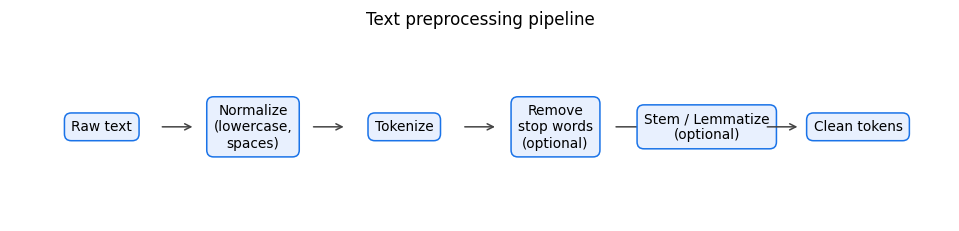

In [8]:
example = ("The students are learning Natural Language Processing, "
           "and they are building amazing AI applications!")

# A picture of the pipeline we will build step by step
fig, ax = plt.subplots(figsize=(11, 2.2))
steps = ["Raw text", "Normalize\n(lowercase,\nspaces)", "Tokenize", "Remove\nstop words\n(optional)",
         "Stem / Lemmatize\n(optional)", "Clean tokens"]
for i, label in enumerate(steps):
    ax.text(i, 0, label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.5", fc="#e8f0fe", ec="#1a73e8"))
    if i < len(steps) - 1:
        ax.annotate("", xy=(i + 0.62, 0), xytext=(i + 0.38, 0),
                    arrowprops=dict(arrowstyle="->", color="#444"))
ax.set_xlim(-0.6, len(steps) - 0.4)
ax.set_ylim(-1, 1)
ax.axis("off")
ax.set_title("Text preprocessing pipeline", fontsize=11)
plt.show()

## 2.1 Text Normalization

**Concept.** Making text consistent: lowercasing, tidying whitespace, handling punctuation, numbers and special characters.

**Everyday analogy.** Writing every name in the attendance sheet in the same format.

We apply each operation separately and print the result after each one.

In [9]:
raw = "  The  STUDENTS paid Rs. 500 for 3 courses!!!   Visit https://example.com :) "
print("0. raw           :", repr(raw))

step1 = raw.lower()
print("1. lowercase     :", repr(step1))

step2 = " ".join(step1.split())          # split() with no argument removes extra whitespace
print("2. whitespace    :", repr(step2))

step3 = re.sub(r"https?://\S+", " URL ", step2)   # replace links with a placeholder token
print("3. URLs          :", repr(step3))

step4 = re.sub(r"[^a-z0-9\s']", " ", step3)        # drop punctuation (keep apostrophes)
print("4. punctuation   :", repr(step4))

step5 = re.sub(r"\d+", " NUM ", step4)             # replace numbers with a placeholder
print("5. numbers       :", repr(step5))

step6 = " ".join(step5.split())
print("6. final spacing :", repr(step6))

0. raw           : '  The  STUDENTS paid Rs. 500 for 3 courses!!!   Visit https://example.com :) '
1. lowercase     : '  the  students paid rs. 500 for 3 courses!!!   visit https://example.com :) '
2. whitespace    : 'the students paid rs. 500 for 3 courses!!! visit https://example.com :)'
3. URLs          : 'the students paid rs. 500 for 3 courses!!! visit  URL  :)'
4. punctuation   : 'the students paid rs  500 for 3 courses    visit         '
5. numbers       : 'the students paid rs   NUM  for  NUM  courses    visit         '
6. final spacing : 'the students paid rs NUM for NUM courses visit'


**Interpretation.** Each step changes the text a little. Replacing a URL or a number by a *placeholder* keeps the information "there was a number here" without keeping every distinct value.

**Why not always remove punctuation, capitals, emojis and numbers?**

| Item | When removing hurts | Example |
|---|---|---|
| Punctuation | Emotion and meaning | "Great!!!" vs "Great."; "Let's eat, Grandma" vs "Let's eat Grandma" |
| Capitals | Names, shouting, acronyms | "Apple" (company) vs "apple" (fruit); "US" vs "us" |
| Emojis | They carry sentiment | "Thanks :)" vs "Thanks :(" |
| Numbers | They are the content | "Rs. 500", "5 stars", "2 out of 10" |

**Common mistake:** removing punctuation *before* sentence splitting, which destroys the sentence boundaries. Order matters.

In [10]:
# Common mistake demo: strip punctuation first, then try to split into sentences
text = "I loved the course. The teacher was great! Will join again?"
no_punct = re.sub(r"[^\w\s]", "", text)
print("Sentences split on '.':", no_punct.split("."))      # one big chunk: boundaries are gone
print("Sentences before cleaning:", re.split(r"(?<=[.!?])\s+", text))

Sentences split on '.': ['I loved the course The teacher was great Will join again']
Sentences before cleaning: ['I loved the course.', 'The teacher was great!', 'Will join again?']


**Practice task.** Add a normalization step that converts the emoticon `:)` into the word `happy_face` *before* punctuation is removed. Why must it happen before?

## 2.2 Tokenization

**Concept.** Splitting text into **tokens**, the units later steps work with.

**Types.**
* *Character-level:* every character is a token.
* *Word-level:* words (and punctuation) are tokens.
* *Sentence-level:* each sentence is a token.

**Analogy.** Cutting a long ribbon into pieces; you can cut it every centimetre (characters), every colour band (words), or at the knots (sentences).

In [11]:
from nltk.tokenize import word_tokenize, sent_tokenize

print("Character tokens (first 15):", list(example)[:15])
print()
print("Word tokens:")
print(word_tokenize(example))
print()
print("Sentence tokens:")
print(sent_tokenize("NLP is exciting. Do you agree? I certainly do!"))

Character tokens (first 15): ['T', 'h', 'e', ' ', 's', 't', 'u', 'd', 'e', 'n', 't', 's', ' ', 'a', 'r']

Word tokens:
['The', 'students', 'are', 'learning', 'Natural', 'Language', 'Processing', ',', 'and', 'they', 'are', 'building', 'amazing', 'AI', 'applications', '!']

Sentence tokens:
['NLP is exciting.', 'Do you agree?', 'I certainly do!']


**Interpretation.** NLTK's `word_tokenize` keeps punctuation marks such as `,` and `!` as separate tokens. Notice that `Processing` and `,` are two tokens.

**Contractions and punctuation.** Watch what happens to "don't", "can't" and "it's".

In [12]:
sentences = [
    "I don't like waiting.",
    "She can't join, but they'll come!",
    "Dr. Smith's lecture ended at 5 p.m.",
]
for s in sentences:
    print(word_tokenize(s))

['I', 'do', "n't", 'like', 'waiting', '.']
['She', 'ca', "n't", 'join', ',', 'but', 'they', "'ll", 'come', '!']
['Dr.', 'Smith', "'s", 'lecture', 'ended', 'at', '5', 'p.m', '.']


**Interpretation.** `don't` becomes `do` + `n't`, where `n't` carries the negation. This is useful: we can later map `n't` to `not` so the negation is not lost.

### Tokenization limitations

| Situation | Problem |
|---|---|
| Multilingual text | Languages such as Chinese or Thai have no spaces between words; Hindi/Punjabi need tokenizers trained for them. NLTK's English tokenizer is not designed for them. |
| Hyphenated words | Is "state-of-the-art" one token or four? |
| URLs, emails | May be split into meaningless fragments |
| Social media | Hashtags (#NLP), mentions (@user), emojis, slang ("gr8", "lolll") |

In [13]:
tricky = ["state-of-the-art model", "Email me at student@nielit.gov.in or visit https://lovnishverma.in",
          "Loved it!!! #NLP @friend gr8 :)"]
for s in tricky:
    print(word_tokenize(s))

['state-of-the-art', 'model']
['Email', 'me', 'at', 'student', '@', 'nielit.gov.in', 'or', 'visit', 'https', ':', '//lovnishverma.in']
['Loved', 'it', '!', '!', '!', '#', 'NLP', '@', 'friend', 'gr8', ':', ')']


**Interpretation.** The email and URL are broken into fragments; the hashtag symbol is separated from the word. For social media text, specialised tokenizers (for example NLTK's `TweetTokenizer`) work better.

In [14]:
from nltk.tokenize import TweetTokenizer
print(TweetTokenizer().tokenize("Loved it!!! #NLP @friend gr8 :)"))

['Loved', 'it', '!', '!', '!', '#NLP', '@friend', 'gr8', ':)']


**Practice task.** Tokenize a sentence in your own language written in English letters and see what happens.

## 2.3 Stop Words

**Concept.** Stop words are very common words (the, is, and, of) that carry little topical information.

**Why remove them?** For tasks like search or topic detection, they add noise and size.

**Why keep them?** For some tasks they carry meaning. The most dangerous example is **negation**.

**Analogy.** When you describe a film to a friend you skip "the", "a", "and" — but you would never skip "not".

In [15]:
from nltk.corpus import stopwords

# 1) A small manual stop-word list
manual_stopwords = {"the", "is", "are", "and", "they", "a", "of"}
tokens = [w.lower() for w in word_tokenize(example) if w.isalpha()]
print("Before:", tokens)
print("After (manual list):", [w for w in tokens if w not in manual_stopwords])

# 2) NLTK's English stop-word list
nltk_stopwords = set(stopwords.words("english"))
print("\nNLTK list size:", len(nltk_stopwords))
print("After (NLTK list):", [w for w in tokens if w not in nltk_stopwords])

Before: ['the', 'students', 'are', 'learning', 'natural', 'language', 'processing', 'and', 'they', 'are', 'building', 'amazing', 'ai', 'applications']
After (manual list): ['students', 'learning', 'natural', 'language', 'processing', 'building', 'amazing', 'ai', 'applications']

NLTK list size: 198
After (NLTK list): ['students', 'learning', 'natural', 'language', 'processing', 'building', 'amazing', 'ai', 'applications']


**Interpretation.** The remaining words ("students", "learning", "natural", ...) are the content-carrying ones.

### The critical example: negation

In [16]:
sentence = "This movie is not good"
tokens = [w.lower() for w in word_tokenize(sentence)]
print("Is 'not' in NLTK's stop words?", "not" in nltk_stopwords)
print("Original tokens      :", tokens)
print("After stop-word removal:", [w for w in tokens if w not in nltk_stopwords])

Is 'not' in NLTK's stop words? True
Original tokens      : ['this', 'movie', 'is', 'not', 'good']
After stop-word removal: ['movie', 'good']


**Interpretation.** After removal we are left with `movie good` — which *looks positive*. The meaning has been reversed. Stop-word removal can silently destroy negation.

**Safer approach:** build a custom list that keeps negations.

In [17]:
negations = {"no", "nor", "not", "never", "neither", "none", "nothing", "n't"}
safe_stopwords = nltk_stopwords - negations - {"don", "didn", "doesn", "isn", "wasn", "weren",
                                              "aren", "couldn", "shouldn", "wouldn", "hasn",
                                              "haven", "hadn", "won", "ain", "mustn", "needn"}
print("Safe removal:", [w for w in tokens if w not in safe_stopwords])

Safe removal: ['movie', 'not', 'good']


| Task | Stop-word removal? |
|---|---|
| Topic classification, search keywords | Often useful |
| Sentiment analysis | Be careful: keep negations (and often keep everything) |
| Transformer models (BERT, GPT) | **Do not remove**: they use full sentences |

**Practice task.** Add "very" to the words you keep (intensifiers like *very* change sentiment strength) and test "very bad".

## 2.4 Stemming and Lemmatization

**Concept.**
* **Stemming** chops word endings with fixed rules to get a *stem* (fast, crude, may not be a real word).
* **Lemmatization** uses a dictionary and grammar to return a real base word, the *lemma* (slower, more accurate).

**Analogy.** Stemming is trimming a branch with scissors; lemmatization is carefully finding where the branch actually joins the tree.

In [18]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["playing", "played", "plays", "studies", "studying", "running", "runs", "better", "good"]
rows = []
for w in words:
    rows.append({"word": w,
                 "stem (Porter)": stemmer.stem(w),
                 "lemma (default=noun)": lemmatizer.lemmatize(w),
                 "lemma (as verb)": lemmatizer.lemmatize(w, pos="v"),
                 "lemma (as adjective)": lemmatizer.lemmatize(w, pos="a")})
pd.DataFrame(rows)

,word,stem (Porter),lemma (default=noun),lemma (as verb),lemma (as adjective)
0,playing,play,playing,play,playing
1,played,play,played,play,played
2,plays,play,play,play,plays
3,studies,studi,study,study,studies
4,studying,studi,studying,study,studying
5,running,run,running,run,running
6,runs,run,run,run,runs
7,better,better,better,better,good
8,good,good,good,good,good


**Interpretation.**

* The stemmer maps `studies` and `studying` to `studi` — **not a dictionary word**, but both forms share it, which is all search often needs.
* The lemmatizer's answer depends on the **part of speech (POS)** you give it. By default it treats words as *nouns*, so `running` stays `running` but `lemmatize("running", pos="v")` gives `run`.
* `better` → `good` works **only** when told it is an adjective. Lemmatizers do not understand context or synonyms by themselves; they only look words up in the WordNet dictionary using the POS you provide.
* The lemmatizer needs the **WordNet** resource, downloaded in our setup cell.

**Common mistake:** calling `lemmatize(word)` without a POS and concluding "lemmatization does not work". Below we let NLTK *guess* POS tags and pass them in.

In [19]:
from nltk import pos_tag
from nltk.corpus import wordnet

def to_wordnet_pos(treebank_tag: str) -> str:
    """Convert a Penn Treebank POS tag (e.g. 'VBG') to a WordNet POS letter."""
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN          # default: noun

sentence = "The children were studying and running quickly"
tagged = pos_tag(word_tokenize(sentence))
print("POS tags:", tagged)
print("Lemmas  :", [lemmatizer.lemmatize(w.lower(), to_wordnet_pos(t)) for w, t in tagged])

POS tags: [('The', 'DT'), ('children', 'NNS'), ('were', 'VBD'), ('studying', 'VBG'), ('and', 'CC'), ('running', 'VBG'), ('quickly', 'RB')]
Lemmas  : ['the', 'child', 'be', 'study', 'and', 'run', 'quickly']


**Interpretation.** With POS information, `children` → `child`, `were` → `be`, `studying` → `study`, `running` → `run`. POS tagging is itself a statistical guess, so lemmatization can still make mistakes.

| | Stemming | Lemmatization |
|---|---|---|
| Output | Often not a real word (`studi`) | A real dictionary word (`study`) |
| Speed | Very fast | Slower |
| Needs POS/dictionary | No | Yes (WordNet) |
| Typical use | Search, quick baselines | When readable, accurate base forms matter |

**Practice task.** Stem and lemmatize: "wolves", "geese", "happily", "universities". Which differences surprise you?

## 2.5 Complete Preprocessing Pipeline

We now combine the steps into one reusable function, `preprocess_text(text)`.

**Design decisions (all documented):**

1. Non-string input (`None`, numbers, `NaN`) → return `""`.
2. Lowercase, replace URLs with `url`, tidy whitespace.
3. Tokenize with NLTK; convert the contraction token `n't` to `not`.
4. Keep only alphabetic tokens (numbers and punctuation dropped; this is a *choice*).
5. Optionally remove stop words, but **never negations**.
6. Optionally lemmatize using POS tags.
7. Return a single string of tokens separated by spaces.

In [20]:
from typing import Any

_STOPWORDS = set(stopwords.words("english"))
# Words we never want to delete: negations (and "very", an intensifier).
# NLTK's list also contains forms such as "didn" / "isn" (what is left of "didn't" / "isn't").
_KEEP = {"no", "nor", "not", "never", "neither", "none", "nothing", "very",
         "don", "didn", "doesn", "isn", "wasn", "weren", "aren", "couldn", "shouldn",
         "wouldn", "hasn", "haven", "hadn", "won", "ain", "mustn", "needn"}
_STOPWORDS_SAFE = _STOPWORDS - _KEEP


def preprocess_text(text: Any, remove_stopwords: bool = True, lemmatize: bool = True) -> str:
    """Clean a piece of text and return a string of normalized tokens.

    Negation words are never removed, because deleting 'not' can flip sentiment.
    Missing or non-string input returns an empty string.
    """
    if not isinstance(text, str) or not text.strip():
        return ""

    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)      # links -> placeholder
    tokens = word_tokenize(text)
    tokens = ["not" if tok == "n't" else tok for tok in tokens]  # keep negation from contractions
    tokens = [tok for tok in tokens if tok.isalpha()]            # drop punctuation and numbers

    if remove_stopwords:
        tokens = [tok for tok in tokens if tok not in _STOPWORDS_SAFE]

    if lemmatize and tokens:
        tagged = pos_tag(tokens)
        tokens = [lemmatizer.lemmatize(tok, to_wordnet_pos(tag)) for tok, tag in tagged]

    return " ".join(tokens)


print(repr(preprocess_text(example)))
print(repr(preprocess_text("I don't like this phone, it's NOT good!!!")))
print(repr(preprocess_text("")))
print(repr(preprocess_text(None)))
print(repr(preprocess_text(float("nan"))))
print(repr(preprocess_text("Visit https://example.com now :)")))

'student learn natural language processing build amaze ai application'
'not like phone not good'
''
''
''
'visit url'


**Interpretation.** The example sentence keeps its content words in base form; negation survives in the second example; empty, `None` and `NaN` inputs give `""` instead of crashing.

### How preprocessing differs by task

| Task | Typical preprocessing |
|---|---|
| Sentiment analysis | Light cleaning; **keep negations**, often keep punctuation/emojis and stop words |
| Search | Lowercase, tokenize, remove stop words, stem or lemmatize |
| Topic classification | Lowercase, remove stop words, optionally lemmatize |
| Transformers | Almost none: raw text with the model's own tokenizer |

**Common mistake:** applying one fixed pipeline to every task.

## 2.6 Practice exercises (Module 2)

Try each before opening the solutions.

1. Write `count_words(text)` that returns the number of word tokens (ignore punctuation).
2. Write `remove_digits(text)` that removes all digits.
3. Write `unique_stems(text)` that returns the sorted set of Porter stems of the words in `text`.
4. Call `preprocess_text` with `remove_stopwords=False` on `"I do not like it"` and explain the difference.
5. Write `longest_token(text)` that returns the longest word token (return `""` for empty input).
6. Write `is_clean(text)` that returns `True` if `preprocess_text(text)` is non-empty.

### Solutions: Module 2 exercises

In [21]:
def count_words(text: str) -> int:
    return len([t for t in word_tokenize(text) if t.isalpha()])

def remove_digits(text: str) -> str:
    return re.sub(r"\d+", "", text)

def unique_stems(text: str) -> list:
    return sorted({stemmer.stem(t.lower()) for t in word_tokenize(text) if t.isalpha()})

def longest_token(text: str) -> str:
    tokens = [t for t in word_tokenize(text) if t.isalpha()]
    return max(tokens, key=len) if tokens else ""

def is_clean(text: str) -> bool:
    return preprocess_text(text) != ""

print(count_words("NLP is fun, isn't it?"))
print(remove_digits("Room 101 has 25 seats"))
print(unique_stems("Players played and plays playing"))
print(repr(longest_token("Tokenization is useful")), repr(longest_token("")))
print(is_clean("the of and"), is_clean("great course"))
print("Ex 4 with stop words kept :", preprocess_text("I do not like it", remove_stopwords=False))
print("Ex 4 with stop words removed:", preprocess_text("I do not like it", remove_stopwords=True))

5
Room  has  seats
['and', 'play', 'player']
'Tokenization' ''
False True
Ex 4 with stop words kept : i do not like it
Ex 4 with stop words removed: not like


**Exercise 4 explanation.** Both versions keep `not`; removing stop words additionally drops `i`, `do`, `it`. Our safe list protects negation but still removes other function words, so use `remove_stopwords=False` for sentiment work where such words might help.

# MODULE 3 — Converting Text into Numerical Features

**The challenge.** Machine learning algorithms work with numbers. Text must be converted into numerical **features** (measurable properties) before a model can use it.

**Analogy.** A teacher cannot average "good effort" and "excellent work" until they are turned into marks. Feature extraction is "turning words into marks".

Our tiny teaching corpus:

* Document 1: "I love machine learning"
* Document 2: "I love natural language processing"
* Document 3: "Machine learning is interesting"

Key terms: a **document** is one text; the **vocabulary** is the list of distinct words across all documents; a **feature** is one measurable property (here, one vocabulary word); a **document-term matrix** has one row per document and one column per vocabulary word.

In [22]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs = [
    "I love machine learning",
    "I love natural language processing",
    "Machine learning is interesting",
]
for i, d in enumerate(docs, start=1):
    print(f"Document {i}: {d}")

Document 1: I love machine learning
Document 2: I love natural language processing
Document 3: Machine learning is interesting


## 3.1 Bag of Words (BoW)

**Concept.** Represent each document by *how many times each vocabulary word appears*, ignoring word order.

**Why it matters.** It is the simplest bridge from text to numbers and is surprisingly strong for many classification tasks.

**Analogy.** Emptying a bag of Scrabble tiles onto a table: you can count the tiles but the original order of letters is lost.

### Step 1: a manual implementation with dictionaries

In [23]:
def tokenize_simple(text: str) -> list:
    """Lowercase and split into alphabetic words."""
    return re.findall(r"[a-z]+", text.lower())

# 1) Build the vocabulary: sorted list of unique words across all documents
vocabulary = sorted({word for d in docs for word in tokenize_simple(d)})
print("Vocabulary:", vocabulary)

# 2) Count words per document using the vocabulary order
manual_matrix = []
for d in docs:
    counts = Counter(tokenize_simple(d))
    manual_matrix.append([counts.get(word, 0) for word in vocabulary])

print(pd.DataFrame(manual_matrix, columns=vocabulary, index=["Doc 1", "Doc 2", "Doc 3"]))

Vocabulary: ['i', 'interesting', 'is', 'language', 'learning', 'love', 'machine', 'natural', 'processing']
       i  interesting  is  language  learning  love  machine  natural  \
Doc 1  1            0   0         0         1     1        1        0   
Doc 2  1            0   0         1         0     1        0        1   
Doc 3  0            1   1         0         1     0        1        0   

       processing  
Doc 1           0  
Doc 2           1  
Doc 3           0  


**Interpretation.** Each row is a document; each column is a word. A `1` under `love` in Doc 1 means "love" appears once there. Documents 1 and 2 share `i` and `love`, so their rows overlap.

### Step 2: the scikit-learn implementation (`CountVectorizer`)

Note: by default `CountVectorizer` lowercases text and its token pattern ignores single-character words, so `i` is **dropped**. This default surprises many beginners; we will see it in the output.

In [24]:
count_vec = CountVectorizer()
bow_matrix = count_vec.fit_transform(docs)        # learn vocabulary AND transform

print("1. Input documents:", docs)
print("\n2. Learned vocabulary (word -> column index):")
print(count_vec.vocabulary_)
print("\n3. Numerical matrix (sparse):")
print(bow_matrix)
print("\n4. Dimensions (documents, features):", bow_matrix.shape)

features = count_vec.get_feature_names_out()
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=features, index=["Doc 1", "Doc 2", "Doc 3"])
print("\nReadable table (safe only because the corpus is tiny):")
print(bow_df)

1. Input documents: ['I love machine learning', 'I love natural language processing', 'Machine learning is interesting']

2. Learned vocabulary (word -> column index):
{'love': 4, 'machine': 5, 'learning': 3, 'natural': 6, 'language': 2, 'processing': 7, 'is': 1, 'interesting': 0}

3. Numerical matrix (sparse):
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 11 stored elements and shape (3, 8)>
  Coords	Values
  (0, 4)	1
  (0, 5)	1
  (0, 3)	1
  (1, 4)	1
  (1, 6)	1
  (1, 2)	1
  (1, 7)	1
  (2, 5)	1
  (2, 3)	1
  (2, 1)	1
  (2, 0)	1

4. Dimensions (documents, features): (3, 8)

Readable table (safe only because the corpus is tiny):
       interesting  is  language  learning  love  machine  natural  processing
Doc 1            0   0         0         1     1        1        0           0
Doc 2            0   0         1         0     1        0        1           1
Doc 3            1   1         0         1     0        1        0           0


**5. Interpreting entries.** Look at the `love` column: it is `1` for Doc 1 and Doc 2, and `0` for Doc 3, because Doc 3 does not contain "love". The entry at row *Doc 3*, column `interesting` is `1`.

**Vocabulary ordering.** Features are stored in **alphabetical order**, and `vocabulary_` maps each word to its column number. Matrix columns must always be matched to `get_feature_names_out()`, never to the order words first appeared in your text.

**Binary vs count features.** `CountVectorizer(binary=True)` records only presence (1) or absence (0). Counts capture repetition; binary ignores it.

In [25]:
binary_vec = CountVectorizer(binary=True)
repeat_docs = ["good good good movie", "good movie"]
print("count :", CountVectorizer().fit_transform(repeat_docs).toarray().tolist())
print("binary:", binary_vec.fit_transform(repeat_docs).toarray().tolist())

count : [[3, 1], [1, 1]]
binary: [[1, 1], [1, 1]]


**Advantages of BoW:** simple, fast, interpretable. **Limitations:** ignores word order ("dog bites man" = "man bites dog"), ignores meaning, produces long mostly-zero rows, and treats frequent but uninformative words as important.

**Common mistake:** assuming the vectorizer keeps every word. Defaults drop one-letter tokens such as `i` and `a`. Fix: `CountVectorizer(token_pattern=r"(?u)\b\w+\b")`.

In [26]:
keep_single = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
keep_single.fit(docs)
print(keep_single.get_feature_names_out())

['i' 'interesting' 'is' 'language' 'learning' 'love' 'machine' 'natural'
 'processing']


**Practice task.** Add a fourth document "I love learning" and re-run the manual and scikit-learn versions. What changes in the vocabulary and matrix shape?

## 3.2 Term Frequency–Inverse Document Frequency (TF-IDF)

**Concept (intuition first).** Counting words overweights common words. TF-IDF scores a word as **high** when it appears *often in this document* but *in few other documents*, and **low** when it appears everywhere.

**Analogy.** If every student in a class says "hello", that word does not identify anyone. If only one student says "quantum", it tells you something about that student.

* **Term frequency (TF):** how often a term appears in a document.
* **Inverse document frequency (IDF):** how *rare* the term is across the corpus. Rare → large IDF.
* **Corpus matters:** the same word can score differently in a different collection.

### The formula used by scikit-learn (defaults)

With `smooth_idf=True`, `n` = number of documents and `df(t)` = number of documents containing term `t`:

$$\text{idf}(t) = \ln\!\left(\frac{1+n}{1+\text{df}(t)}\right) + 1$$

$$\text{tf-idf}(t,d) = \text{tf}(t,d) \times \text{idf}(t)$$

Here `tf(t,d)` is the raw count. Then each document's row is **L2-normalized** (divided by the length of the row vector, so the squares of its values sum to 1). Normalization makes long and short documents comparable. (L1 normalization would instead make the absolute values sum to 1.) The `+1` means even terms found in every document keep a small positive weight.

In [27]:
tfidf_vec = TfidfVectorizer()
tfidf_matrix = tfidf_vec.fit_transform(docs)

print("Feature names:", list(tfidf_vec.get_feature_names_out()))
print("Matrix type  :", type(tfidf_matrix).__name__, "| shape:", tfidf_matrix.shape)
print("\nSparse representation (only non-zero entries are stored):")
print(tfidf_matrix)

tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vec.get_feature_names_out(),
                        index=["Doc 1", "Doc 2", "Doc 3"]).round(3)
print("\nDense view (tiny teaching dataset only):")
print(tfidf_df)

Feature names: ['interesting', 'is', 'language', 'learning', 'love', 'machine', 'natural', 'processing']
Matrix type  : csr_matrix | shape: (3, 8)

Sparse representation (only non-zero entries are stored):
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 11 stored elements and shape (3, 8)>
  Coords	Values
  (0, 4)	0.5773502691896257
  (0, 5)	0.5773502691896257
  (0, 3)	0.5773502691896257
  (1, 4)	0.4020402441612698
  (1, 6)	0.5286346066596935
  (1, 2)	0.5286346066596935
  (1, 7)	0.5286346066596935
  (2, 5)	0.4280460350631185
  (2, 3)	0.4280460350631185
  (2, 1)	0.5628290964997665
  (2, 0)	0.5628290964997665

Dense view (tiny teaching dataset only):
       interesting     is  language  learning   love  machine  natural  \
Doc 1        0.000  0.000     0.000     0.577  0.577    0.577    0.000   
Doc 2        0.000  0.000     0.529     0.000  0.402    0.000    0.529   
Doc 3        0.563  0.563     0.000     0.428  0.000    0.428    0.000   

       processing  
Doc 1       

**Interpretation.** Compare the `love` column with `language`, `natural`, `processing`: `love` appears in two of three documents, so it has a **lower IDF** than words appearing in only one document. Within Doc 2, the rare words get higher weights than `love`.

**Verify the formula by hand** (this is a good habit: never trust a formula you have not checked once).

In [28]:
n_docs = len(docs)
term = "love"
df_love = sum(term in tokenize_simple(d) for d in docs)             # documents containing 'love'
idf_love = np.log((1 + n_docs) / (1 + df_love)) + 1
print(f"df(love)={df_love}, idf(love)={idf_love:.4f}")
print("scikit-learn idf:", round(float(tfidf_vec.idf_[list(tfidf_vec.get_feature_names_out()).index(term)]), 4))
print("Row L2 norms (should all be 1.0):", np.linalg.norm(tfidf_matrix.toarray(), axis=1).round(3))

df(love)=2, idf(love)=1.2877
scikit-learn idf: 1.2877
Row L2 norms (should all be 1.0): [1. 1. 1.]


### Sparse matrices and memory

Most entries in a document-term matrix are zero. A **sparse matrix** stores only the non-zero entries. A real corpus of 100,000 documents with 50,000 words would need 5 billion numbers as a dense array (many gigabytes), but only the few million non-zero ones as a sparse matrix.

**Common mistake:** calling `.toarray()` on a big matrix, which can crash a Colab session. Keep matrices sparse; scikit-learn models accept them directly. Only convert tiny examples for display.

In [29]:
dense_cells = 100_000 * 50_000
print(f"Dense float64 size for 100,000 x 50,000: {dense_cells * 8 / 1e9:.0f} GB")
print("Our tiny matrix: stored non-zeros =", tfidf_matrix.nnz, "of", tfidf_matrix.shape[0] * tfidf_matrix.shape[1])

Dense float64 size for 100,000 x 50,000: 40 GB
Our tiny matrix: stored non-zeros = 11 of 24


## 3.3 Compare BoW and TF-IDF

| | Bag of Words | TF-IDF |
|---|---|---|
| How it works | Counts words per document | Counts, weighted by how rare the word is in the corpus, then normalized |
| Values | Raw counts (integers) | Weighted decimals |
| Interpretability | Very easy: "appears 2 times" | Easy but less direct: "important in this document" |
| Advantages | Simple, fast | Down-weights very common words |
| Limitations | Common words dominate; ignores order | Still ignores order and meaning; depends on corpus |
| Typical uses | Quick baselines, spam filters | Search ranking, classification, recommenders |

### Visual comparison

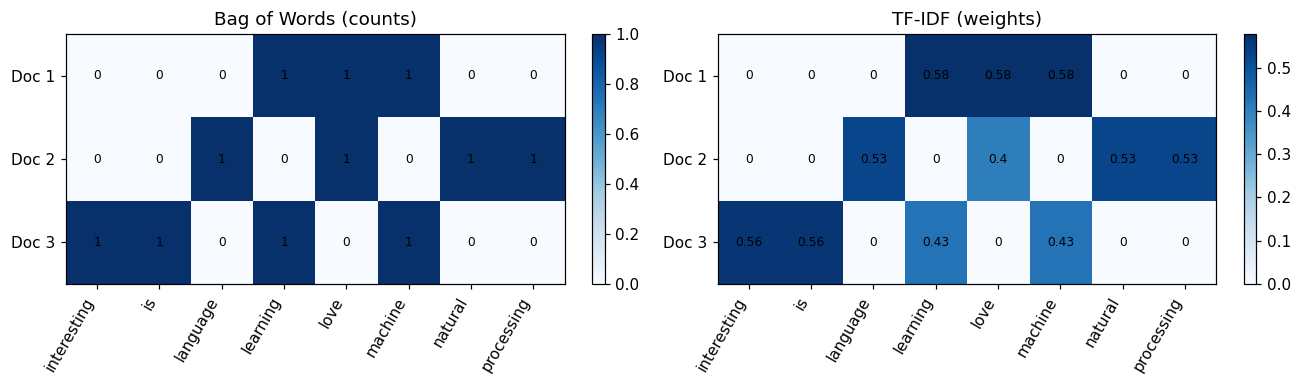

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (title, frame) in zip(axes, [("Bag of Words (counts)", bow_df),
                                      ("TF-IDF (weights)", tfidf_df.reindex(columns=bow_df.columns))]):
    image = ax.imshow(frame.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(frame.columns)))
    ax.set_xticklabels(frame.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(frame.index)))
    ax.set_yticklabels(frame.index)
    ax.set_title(title)
    for r in range(frame.shape[0]):
        for c in range(frame.shape[1]):
            ax.text(c, r, f"{frame.values[r, c]:.2g}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

**Interpretation.** Darker cells mean larger values. BoW shows 1s where a word occurs. TF-IDF varies the shade: words found in fewer documents get higher weights. (Single-letter `i` is absent from both because of the default token rule.)

## 3.4 Practical Feature Engineering

### Unigrams, bigrams and `ngram_range`

A **unigram** is one word; a **bigram** is two consecutive words. Bigrams capture a little word order: "not good" becomes its own feature.

In [31]:
bigram_vec = CountVectorizer(ngram_range=(1, 2))
bigram_vec.fit(["not good at all", "very good indeed"])
print("Unigrams + bigrams:", list(bigram_vec.get_feature_names_out()))

Unigrams + bigrams: ['all', 'at', 'at all', 'good', 'good at', 'good indeed', 'indeed', 'not', 'not good', 'very', 'very good']


**Interpretation.** `ngram_range=(1, 2)` means "use n-grams of length 1 to 2". The bigram `not good` lets a model learn that the *pair* is negative, even if `good` alone is positive. Cost: the vocabulary grows quickly.

### Filtering the vocabulary: `min_df` and `max_features`

* `min_df=2`: ignore words appearing in fewer than 2 documents (removes typos and one-off words).
* `max_features=5`: keep only the 5 most frequent words overall.

In [32]:
corpus = ["good phone", "good battery", "bad phone", "good camera zzzqx", "bad battery"]
print("all words     :", list(CountVectorizer().fit(corpus).get_feature_names_out()))
print("min_df=2      :", list(CountVectorizer(min_df=2).fit(corpus).get_feature_names_out()))
print("max_features=3:", list(CountVectorizer(max_features=3).fit(corpus).get_feature_names_out()))

all words     : ['bad', 'battery', 'camera', 'good', 'phone', 'zzzqx']
min_df=2      : ['bad', 'battery', 'good', 'phone']
max_features=3: ['bad', 'battery', 'good']


**Interpretation.** `zzzqx` (a one-off typo) and `camera` vanish with `min_df=2`. Smaller vocabularies train faster and often generalize better, but too much filtering throws away useful rare words.

### Train/test data leakage

**Concept.** *Data leakage* means information from the test set influences training. If you fit a vectorizer on **all** text, then split, the vocabulary and IDF values were learned partly from test documents, which makes evaluation look better than it should.

**Analogy.** A student who has seen the exam questions in advance.

**Rule:** `fit` (or `fit_transform`) on **training** data only; `transform` on test data.

In [33]:
from sklearn.model_selection import train_test_split

all_text = ["good phone", "great battery", "bad screen", "awful camera",
            "good camera", "bad battery", "great screen", "awful phone"]
train_text, test_text = train_test_split(all_text, test_size=0.25, random_state=SEED)

# WRONG (leaky): learns vocabulary from every document, including the test ones
leaky = CountVectorizer().fit(all_text)

# RIGHT: learns only from training documents
correct = CountVectorizer().fit(train_text)

print("Train docs:", train_text)
print("Test docs :", test_text)
print("\nLeaky vocabulary  :", sorted(leaky.vocabulary_))
print("Correct vocabulary:", sorted(correct.vocabulary_))
print("Words the correct vectorizer never saw:", sorted(set(leaky.vocabulary_) - set(correct.vocabulary_)))

Train docs: ['good phone', 'awful phone', 'bad screen', 'good camera', 'awful camera', 'great screen']
Test docs : ['great battery', 'bad battery']

Leaky vocabulary  : ['awful', 'bad', 'battery', 'camera', 'good', 'great', 'phone', 'screen']
Correct vocabulary: ['awful', 'bad', 'camera', 'good', 'great', 'phone', 'screen']
Words the correct vectorizer never saw: ['battery']


**Interpretation.** The correct vectorizer simply *ignores* unseen words in test documents, exactly as it would in real use. Later we use a scikit-learn `Pipeline`, which makes it impossible to forget this rule.

## 3.5 Practice exercises (Module 3)

1. Build a `CountVectorizer` for `["red apple", "green apple", "red cherry"]` and print the feature names.
2. For the same corpus, which word has the lowest IDF in `TfidfVectorizer`? Explain why.
3. Use `ngram_range=(2, 2)` to list only bigrams for `["I love NLP", "I love Python"]`.
4. Use `min_df=2` and show which words survive in `["a b c", "a b d", "a e f"]` (use `token_pattern=r"(?u)\b\w+\b"`).
5. Compute the IDF of a word that appears in 1 of 4 documents with the scikit-learn formula.
6. Explain in one sentence why fitting a vectorizer on test data is a mistake.

### Solutions: Module 3 exercises

In [34]:
# 1
ex1 = CountVectorizer().fit(["red apple", "green apple", "red cherry"])
print("1:", list(ex1.get_feature_names_out()))

# 2: 'apple' and 'red' each appear in 2 of 3 documents, so they have the lowest (equal) IDF
ex2 = TfidfVectorizer().fit(["red apple", "green apple", "red cherry"])
idf_table = {w: round(float(v), 3) for w, v in zip(ex2.get_feature_names_out(), ex2.idf_)}
print("2:", idf_table, "-> lowest IDF:", min(idf_table, key=idf_table.get), "(ties possible: apple, red)")

# 3
ex3 = CountVectorizer(ngram_range=(2, 2)).fit(["I love NLP", "I love Python"])
print("3:", list(ex3.get_feature_names_out()))

# 4
ex4 = CountVectorizer(min_df=2, token_pattern=r"(?u)\b\w+\b").fit(["a b c", "a b d", "a e f"])
print("4:", list(ex4.get_feature_names_out()))

# 5: n = 4, df = 1  ->  ln((1+4)/(1+1)) + 1
print("5:", round(float(np.log((1 + 4) / (1 + 1)) + 1), 4))

print("6: Because the test set must stay unseen; fitting on it leaks information and inflates scores.")

1: ['apple', 'cherry', 'green', 'red']
2: {'apple': 1.288, 'cherry': 1.693, 'green': 1.693, 'red': 1.288} -> lowest IDF: apple (ties possible: apple, red)
3: ['love nlp', 'love python']
4: ['a', 'b']
5: 1.9163
6: Because the test set must stay unseen; fitting on it leaks information and inflates scores.


# MODULE 4 — Sentiment Analysis Using Python

**Concept.** *Sentiment analysis* decides the attitude expressed in text: **positive**, **negative**, or sometimes **neutral**.

**Why it matters.** Companies read thousands of reviews and survey answers; sentiment analysis summarizes them.

**Analogy.** A teacher skimming feedback forms and sorting them into "happy" and "unhappy" piles.

* **Binary classification:** two classes (positive / negative). This is what we build.
* **Multiclass classification:** three or more classes (positive / neutral / negative, or 1–5 stars).

**Why it is hard**

| Challenge | Example |
|---|---|
| Negation | "not bad" is mildly positive |
| Sarcasm | "Oh great, it broke after one day." |
| Context | "The movie was *sick*!" (slang praise) |
| Domain language | "unpredictable" is good for a thriller, bad for a washing machine |

**Two approaches**

| | Rule-based (dictionary) | Supervised machine learning |
|---|---|---|
| Idea | Hand-made word lists with scores | Learn word weights from labelled examples |
| Needs labelled data | No | Yes |
| Transparency | Very high | Moderate (weights can be inspected) |
| Weakness | Misses context, negation, domain words | Needs enough representative data |

## 4.1 Build a Small Dataset

We create a tiny dataset by hand, drawn from five scenarios: product reviews, online shopping, education feedback, customer support, and movie reviews. It is small enough to read completely.

> **Important.** This is a demonstration dataset written for teaching. It is **not representative** of real customers and **cannot establish real-world performance**. Any score computed from it is only a demonstration of the evaluation workflow.

In [35]:
sentiment_data = [
    # --- product reviews ---
    ("The battery life is excellent and the screen is gorgeous", "positive"),
    ("Amazing phone, I love the camera", "positive"),
    ("Very comfortable headphones with great sound", "positive"),
    ("The laptop is fast and works perfectly", "positive"),
    ("Terrible battery, it dies in two hours", "negative"),
    ("The screen cracked after one week, very disappointing", "negative"),
    ("Poor sound quality and the headphones feel cheap", "negative"),
    ("The laptop is slow and keeps crashing", "negative"),
    # --- online shopping ---
    ("Delivery was quick and the packaging was perfect", "positive"),
    ("Great price and the product arrived early", "positive"),
    ("Easy checkout and helpful tracking updates", "positive"),
    ("Excellent value, I will shop here again", "positive"),
    ("My order arrived late and the box was damaged", "negative"),
    ("The item was not as described, a complete waste of money", "negative"),
    ("Checkout kept failing and the website was confusing", "negative"),
    ("Wrong product delivered and no refund yet", "negative"),
    # --- education feedback ---
    ("The teacher explains concepts clearly and patiently", "positive"),
    ("I enjoyed the hands-on labs and learned a lot", "positive"),
    ("Well organized course with useful assignments", "positive"),
    ("The workshop was inspiring and very practical", "positive"),
    ("The lectures were boring and hard to follow", "negative"),
    ("Too much homework and unclear instructions", "negative"),
    ("The course content was outdated and confusing", "negative"),
    ("I did not learn anything useful from this session", "negative"),
    # --- customer support ---
    ("Support resolved my issue quickly, very friendly staff", "positive"),
    ("The agent was polite and solved the problem in minutes", "positive"),
    ("Helpful and professional service, thank you", "positive"),
    ("Fast response and a clear explanation", "positive"),
    ("I waited two hours and nobody answered my call", "negative"),
    ("The agent was rude and could not fix anything", "negative"),
    ("Useless support, they ignored my emails", "negative"),
    ("Slow replies and no real solution", "negative"),
    # --- movie reviews ---
    ("A brilliant film with a touching story", "positive"),
    ("Wonderful acting and a beautiful soundtrack", "positive"),
    ("I loved every minute, a must watch", "positive"),
    ("Funny, smart and full of heart", "positive"),
    ("The plot was dull and the ending was predictable", "negative"),
    ("Awful acting and a boring script", "negative"),
    ("I hated this movie, a total waste of time", "negative"),
    ("Long, messy and not entertaining at all", "negative"),
    # --- more examples (product, shopping, education, support, movies) ---
    ("Great sound and the battery lasts all day", "positive"),
    ("The camera is excellent and the photos look amazing", "positive"),
    ("Very good phone for the price, I love it", "positive"),
    ("Sturdy build, fast charging and a great display", "positive"),
    ("Poor build quality and the buttons feel cheap", "negative"),
    ("The speaker stopped working after two days, terrible", "negative"),
    ("Slow performance and the battery drains quickly", "negative"),
    ("Bad display and a very disappointing camera", "negative"),
    ("Fast shipping and the item was exactly as described", "positive"),
    ("Lovely product, great packaging and quick delivery", "positive"),
    ("Smooth website and an easy return process", "positive"),
    ("Good discounts and the order arrived on time", "positive"),
    ("The parcel was lost and customer care was useless", "negative"),
    ("Terrible packaging, the product arrived broken", "negative"),
    ("Slow delivery and the tracking never updated", "negative"),
    ("Bad experience, the seller never replied", "negative"),
    ("Great lectures and very helpful notes", "positive"),
    ("The instructor was friendly, clear and inspiring", "positive"),
    ("Excellent course, I learned a lot and enjoyed every class", "positive"),
    ("Good examples and a very useful project", "positive"),
    ("Boring slides and a confusing explanation", "negative"),
    ("Poor organisation, the class started late every day", "negative"),
    ("The exams were unfair and the feedback was useless", "negative"),
    ("Terrible audio in the online class, I could not follow", "negative"),
    ("Quick, polite and very helpful support team", "positive"),
    ("Excellent service, my problem was solved in minutes", "positive"),
    ("Great communication and a friendly agent", "positive"),
    ("Good support, they answered all my questions", "positive"),
    ("Rude staff and a very slow response", "negative"),
    ("Terrible service, nobody solved my problem", "negative"),
    ("Poor communication and no follow up", "negative"),
    ("Bad support, I was transferred five times", "negative"),
    ("A great movie with excellent acting", "positive"),
    ("Beautiful story, I loved the music", "positive"),
    ("Brilliant direction and a wonderful cast", "positive"),
    ("Good fun, smart jokes and a great ending", "positive"),
    ("A boring movie with terrible acting", "negative"),
    ("Bad script, a dull story and a weak ending", "negative"),
    ("Poor editing and a confusing plot", "negative"),
    ("I hated the ending, a total waste", "negative"),
    ("The service was not good at all", "negative"),
    ("The product is not bad, I like it", "positive"),
    ("I was not impressed by the quality", "negative"),
    ("Not slow at all, it works great", "positive"),
    ("The teacher is not boring, the lessons are fun", "positive"),
    ("This is not what I wanted, very bad", "negative"),
    ("Not happy with the delivery, it was late", "negative"),
    ("No problems at all, everything was perfect", "positive"),
    ("Not worth the money, poor quality", "negative"),
    ("I would not recommend this, it was awful", "negative"),
    ("Nothing to complain about, great experience", "positive"),
    ("The battery is not good and the screen is poor", "negative"),
    # --- negation examples (a known hard case) ---
    ("The food was not good", "negative"),
    ("This is not bad at all, I am pleasantly surprised", "positive"),
    ("I am not happy with the service", "negative"),
    ("Not disappointed, the quality is great", "positive"),
]
sentiment_df = pd.DataFrame(sentiment_data, columns=["text", "label"])

print("Shape:", sentiment_df.shape)
print("Missing values:\n", sentiment_df.isna().sum().to_string())
print("Duplicate texts:", sentiment_df["text"].duplicated().sum())
print("\nClass counts:\n", sentiment_df["label"].value_counts().to_string())
sentiment_df.sample(5, random_state=SEED)

Shape: (96, 2)
Missing values:
 text     0
label    0
Duplicate texts: 0

Class counts:
 label
negative    49
positive    47


,text,label
80,The service was not good at all,negative
77,"Bad script, a dull story and a weak ending",negative
73,"Beautiful story, I loved the music",positive
94,I am not happy with the service,negative
33,Wonderful acting and a beautiful soundtrack,positive


**Interpretation.** We verified the schema (two columns, `text` and `label`), checked for missing values and duplicates, and confirmed the classes are nearly balanced. These simple checks catch many real-world data problems early. Notice that some rows deliberately contain negation ("not good", "not bad").

## 4.2 Baseline Sentiment Analysis (dictionary-based)

**Concept.** Give each known word a score (+1 for positive words, −1 for negative words) and add up the scores of a sentence.

**Why start here?** A transparent baseline tells you what a more complex model must beat, and shows exactly *why* it decided what it did.

In [36]:
POSITIVE_WORDS = {"excellent", "gorgeous", "amazing", "love", "loved", "great", "comfortable", "fast",
                  "perfectly", "perfect", "quick", "helpful", "easy", "enjoyed", "clearly", "useful",
                  "inspiring", "brilliant", "wonderful", "beautiful", "funny", "friendly", "polite",
                  "professional", "good", "happy", "value", "touching", "smart", "pleasantly"}
NEGATIVE_WORDS = {"terrible", "disappointing", "poor", "cheap", "slow", "crashing", "late", "damaged",
                  "waste", "confusing", "wrong", "boring", "hard", "unclear", "outdated", "rude",
                  "useless", "ignored", "dull", "predictable", "awful", "hated", "messy", "dies",
                  "cracked", "failing", "disappointed", "bad"}

def lexicon_sentiment(text: str):
    """Return (label, score, contributions) using simple word counting."""
    words = re.findall(r"[a-z']+", text.lower())
    contributions = {}
    for word in words:
        if word in POSITIVE_WORDS:
            contributions[word] = contributions.get(word, 0) + 1
        elif word in NEGATIVE_WORDS:
            contributions[word] = contributions.get(word, 0) - 1
    score = sum(contributions.values())
    label = "positive" if score > 0 else "negative" if score < 0 else "neutral"
    return label, score, contributions

for sentence in ["The teacher was great and the labs were useful",
                 "The food was not good",
                 "Not disappointed, the quality is great"]:
    label, score, parts = lexicon_sentiment(sentence)
    print(f"{label:>8} (score {score:+d})  {parts}   <- {sentence}")

positive (score +2)  {'great': 1, 'useful': 1}   <- The teacher was great and the labs were useful
positive (score +1)  {'good': 1}   <- The food was not good
 neutral (score +0)  {'disappointed': -1, 'great': 1}   <- Not disappointed, the quality is great


**Interpretation.** The `contributions` dictionary shows *exactly* which words pushed the score. The second sentence contains `good`, so the baseline wrongly rates it positive: it cannot see the `not`. This is the **negation** limitation. Other limits: sarcasm ("Great, it broke") fools it, ambiguous words depend on context, and the word lists are domain-specific (we wrote them for this dataset).

Let us measure the baseline on our data. Neutral predictions (score 0) count as wrong here because the dataset has no neutral class.

In [37]:
baseline_preds = [lexicon_sentiment(t)[0] for t in sentiment_df["text"]]
baseline_accuracy = np.mean(np.array(baseline_preds) == sentiment_df["label"].values)
print(f"Baseline accuracy on the whole demo dataset: {baseline_accuracy:.2f}")
print("(The word lists were written while looking at this data, so this number is optimistic.)")
wrong = sentiment_df[np.array(baseline_preds) != sentiment_df["label"].values]
print("\nExamples the baseline gets wrong:")
for text, label in wrong.head(5).itertuples(index=False):
    print(f"  expected {label:>8}: {text}")

Baseline accuracy on the whole demo dataset: 0.86
(The word lists were written while looking at this data, so this number is optimistic.)

Examples the baseline gets wrong:
  expected negative: I did not learn anything useful from this session
  expected negative: I waited two hours and nobody answered my call
  expected negative: The service was not good at all
  expected positive: The product is not bad, I like it
  expected negative: I was not impressed by the quality


**Common mistake:** evaluating on the same data you used to design the rules. Here that makes the baseline look better than it would on new text.

## 4.3 Machine Learning Sentiment Classifier

**Concept.** *Supervised learning* means learning from examples that come with correct answers (**labels**). The model adjusts internal weights so its predictions match the labels, then we test it on unseen data.

**Logistic Regression** (despite its name it is a *classifier*) computes a weighted sum of the features and converts it into a probability between 0 and 1.

**Pipeline.** A scikit-learn `Pipeline` chains steps (vectorizer → classifier). When you call `fit` it fits every step on the **training data only**, and `predict` applies the learned steps to new text. This prevents the leakage we studied in Module 3.

**Steps**

1. Split data into train and test sets (stratified, so both contain both classes in equal proportions).
2. Fit the pipeline on the training set.
3. Predict on the test set.
4. Compute metrics.

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

X = sentiment_df["text"]
y = sentiment_df["label"]

# stratify=y keeps the positive/negative ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Train class counts:", y_train.value_counts().to_dict())
print("Test  class counts:", y_test.value_counts().to_dict())

sentiment_model = Pipeline([
    # ngram_range=(1,2) lets the model see pairs like "not good"
    # token_pattern keeps 1-letter words; sublinear_tf dampens repeated words
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b", sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
sentiment_model.fit(X_train, y_train)      # vectorizer learns from TRAINING text only
y_pred = sentiment_model.predict(X_test)   # test text is only transformed, never fitted on
print("\nPredictions made for", len(y_pred), "test examples.")

Train size: 72 | Test size: 24
Train class counts: {'negative': 37, 'positive': 35}
Test  class counts: {'positive': 12, 'negative': 12}

Predictions made for 24 test examples.


### Evaluation metrics, with analogies

Imagine a spam filter that flags emails. We call **positive** the class we care about finding (here we will report for the label `positive`).

| Metric | Question it answers | Analogy |
|---|---|---|
| **Accuracy** | Of all predictions, how many were right? | The fraction of exam questions you got right |
| **Precision** | Of the items I *labelled* positive, how many truly were? | A fisherman who says "I caught salmon": how many of the fish in the net are really salmon? |
| **Recall** | Of all the truly positive items, how many did I *find*? | Of all the salmon in the river, how many did the fisherman catch? |
| **F1-score** | One number balancing precision and recall (harmonic mean) | A combined grade that drops sharply if either skill is poor |
| **Confusion matrix** | A table of right and wrong predictions per class | A mark sheet showing which mistakes were made |

`zero_division=0` tells scikit-learn what to report when a ratio would divide by zero (for example precision when nothing was predicted positive), avoiding warnings.

In [39]:
labels_order = ["negative", "positive"]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label="positive", zero_division=0)
rec = recall_score(y_test, y_pred, pos_label="positive", zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label="positive", zero_division=0)

print(f"Accuracy : {acc:.2f}")
print(f"Precision: {prec:.2f}  (class = positive)")
print(f"Recall   : {rec:.2f}  (class = positive)")
print(f"F1-score : {f1:.2f}  (class = positive)")

cm = confusion_matrix(y_test, y_pred, labels=labels_order)
print("\nConfusion matrix (rows = true, columns = predicted):")
print(pd.DataFrame(cm, index=[f"true {l}" for l in labels_order],
                   columns=[f"pred {l}" for l in labels_order]))

print("\nFull report:")
print(classification_report(y_test, y_pred, labels=labels_order, zero_division=0))

Accuracy : 0.71
Precision: 0.73  (class = positive)
Recall   : 0.67  (class = positive)
F1-score : 0.70  (class = positive)

Confusion matrix (rows = true, columns = predicted):
               pred negative  pred positive
true negative              9              3
true positive              4              8

Full report:
              precision    recall  f1-score   support

    negative       0.69      0.75      0.72        12
    positive       0.73      0.67      0.70        12

    accuracy                           0.71        24
   macro avg       0.71      0.71      0.71        24
weighted avg       0.71      0.71      0.71        24



**Interpretation.** Read the confusion matrix first: the diagonal holds correct predictions, off-diagonal cells are mistakes.

**Be careful with these numbers.** The test set contains only about two dozen sentences, so a single sentence changes accuracy by roughly 4 percentage points. The scores show that the *workflow runs*; they do not show that the model would work well on real customers.

> **Classroom demonstration vs production system.** A production sentiment system needs thousands of labelled examples from the real domain, representative of all user groups, cross-validation or a larger held-out set, monitoring after deployment, and handling of sarcasm, multiple languages and bias. Do not claim real-world accuracy from a dataset like this.

### See what the model learned

In [40]:
vectorizer = sentiment_model.named_steps["tfidf"]
classifier = sentiment_model.named_steps["clf"]
feature_names = vectorizer.get_feature_names_out()
# For a binary model, classes_[1] is the "positive" class, so positive coefficients push toward positive
assert list(classifier.classes_) == ["negative", "positive"]
order = np.argsort(classifier.coef_[0])
print("Words/phrases pushing toward NEGATIVE:", list(feature_names[order[:8]]))
print("Words/phrases pushing toward POSITIVE:", list(feature_names[order[-8:]][::-1]))

Words/phrases pushing toward NEGATIVE: ['terrible', 'poor', 'was not', 'not', 'was', 'not good', 'the', 'slow']
Words/phrases pushing toward POSITIVE: ['great', 'excellent', 'very', 'is', 'helpful', 'and very', 'fast', 'a great']


### A reusable prediction function with input validation

In [41]:
def predict_sentiment(text, model=sentiment_model) -> dict:
    """Predict sentiment for one piece of text.

    Returns a dictionary with the label, the model's probability for each class
    and a short plain-English explanation. Raises ValueError for unusable input.
    """
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please provide a non-empty piece of text.")
    probabilities = model.predict_proba([text])[0]
    class_names = list(model.classes_)
    best = int(np.argmax(probabilities))
    label = class_names[best]
    confidence = float(probabilities[best])
    explanation = (f"The model leans {label} with probability {confidence:.0%}. "
                   "On a tiny training set this is a rough guide, not a fact.")
    return {"label": label, "probabilities": {c: round(float(p), 3) for c, p in zip(class_names, probabilities)},
            "explanation": explanation}

for sentence in ["The course was wonderful and I learned a lot",
                 "The delivery was late and the product was damaged",
                 "The food was not good"]:
    result = predict_sentiment(sentence)
    print(result["label"], result["probabilities"], "<-", sentence)

try:
    predict_sentiment("   ")
except ValueError as error:
    print("Input check works:", error)

positive {'negative': 0.412, 'positive': 0.588} <- The course was wonderful and I learned a lot
negative {'negative': 0.588, 'positive': 0.412} <- The delivery was late and the product was damaged
negative {'negative': 0.67, 'positive': 0.33} <- The food was not good
Input check works: Please provide a non-empty piece of text.


**Interpretation.** The function refuses empty input instead of crashing mysteriously, and shows probabilities so users can see when the model is unsure (values near 50%).

**Common mistake:** treating a probability as certainty, or calling `fit` again on test text.

## 4.4 Visual Evaluation

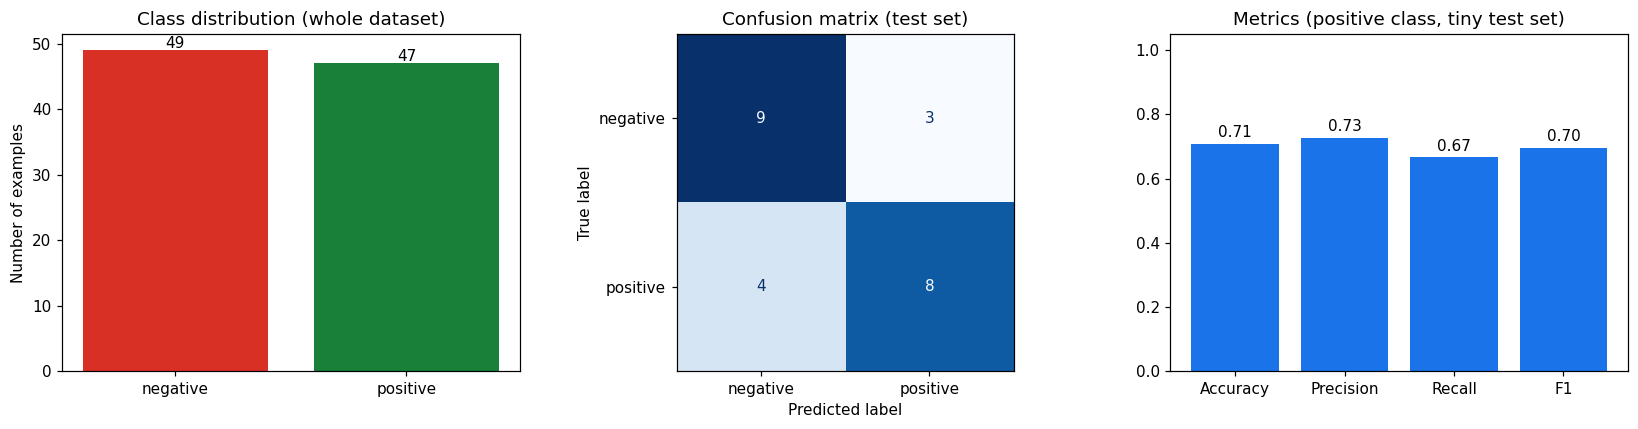

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Class distribution
counts = sentiment_df["label"].value_counts().reindex(labels_order)
axes[0].bar(counts.index, counts.values, color=["#d93025", "#188038"])
axes[0].set_title("Class distribution (whole dataset)")
axes[0].set_ylabel("Number of examples")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 0.3, str(v), ha="center")

# 2) Confusion matrix
ConfusionMatrixDisplay(cm, display_labels=labels_order).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion matrix (test set)")

# 3) Evaluation summary
metrics = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}
axes[2].bar(metrics.keys(), metrics.values(), color="#1a73e8")
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Metrics (positive class, tiny test set)")
for i, v in enumerate(metrics.values()):
    axes[2].text(i, v + 0.02, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.show()

**Interpretation.** (1) The classes are balanced, so accuracy is not misleading here. (2) The confusion matrix shows where mistakes occur. (3) The bars summarize the metrics. With only about two dozen test sentences, treat the heights as illustrations, not as a promise.

**Accessibility tip:** the charts use text labels, not just colours, so they are readable for colour-blind learners.

### Examine the misclassified examples

In [43]:
test_results = pd.DataFrame({"text": X_test.values, "true": y_test.values, "predicted": y_pred})
errors = test_results[test_results["true"] != test_results["predicted"]]
print(f"{len(errors)} misclassified out of {len(test_results)} test examples")
errors if len(errors) else print("No mistakes on this particular split. That does NOT mean the model is perfect.")

7 misclassified out of 24 test examples


,text,true,predicted
7,The agent was polite and solved the problem in...,positive,negative
8,Boring slides and a confusing explanation,negative,positive
12,"Funny, smart and full of heart",positive,negative
13,Bad display and a very disappointing camera,negative,positive
15,"Good support, they answered all my questions",positive,negative
21,"This is not what I wanted, very bad",negative,positive
23,Good discounts and the order arrived on time,positive,negative


## 4.5 Student Exercises (Module 4)

1. **Add new examples.** Append six new labelled sentences (three positive, three negative) to the dataset and retrain.
2. **Predict unseen reviews.** Write five brand-new reviews and predict them with `predict_sentiment`.
3. **Compare BoW with TF-IDF.** Build the same pipeline with `CountVectorizer` instead of `TfidfVectorizer` and compare accuracy.
4. **Examine misclassified examples.** Predict *all* the texts with the trained model (note: that includes training data!) and explain why training accuracy is not a fair test.
5. **Bias and limitations.** List three ways this dataset could be biased or unrepresentative.

### Solutions: Module 4 exercises

In [44]:
# 1) Add new examples and retrain (with a fresh split)
extra = pd.DataFrame([
    ("Superb service and a lovely product", "positive"),
    ("Really enjoyed the interactive lessons", "positive"),
    ("Best purchase I have made this year", "positive"),
    ("The app keeps freezing, so frustrating", "negative"),
    ("Dirty room and unhelpful staff", "negative"),
    ("Worst lecture ever, a total mess", "negative"),
], columns=["text", "label"])
bigger_df = pd.concat([sentiment_df, extra], ignore_index=True)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    bigger_df["text"], bigger_df["label"], test_size=0.25, random_state=SEED, stratify=bigger_df["label"])
model_ex1 = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b")),
                      ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]).fit(Xb_train, yb_train)
print("1) Retrained on", len(Xb_train), "examples; test accuracy:",
      round(accuracy_score(yb_test, model_ex1.predict(Xb_test)), 2))

# 2) Unseen reviews
for review in ["Lovely staff and fantastic food", "The package never arrived and nobody helped",
               "An okay film, nothing special", "Absolutely fantastic teacher", "The worst app I have used"]:
    print("2)", predict_sentiment(review)["label"], "<-", review)
print("   Some of these may be wrong: words never seen in training (e.g. 'fantastic') give the model little to go on.")

# 3) BoW vs TF-IDF on the original split
bow_model = Pipeline([("bow", CountVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b")),
                      ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]).fit(X_train, y_train)
print("3) BoW accuracy:", round(accuracy_score(y_test, bow_model.predict(X_test)), 2),
      "| TF-IDF accuracy:", round(acc, 2), "(differences this small are not meaningful)")

# 4) Training accuracy is optimistic: the model has already seen these sentences
print("4) Accuracy on ALL texts (includes training data):",
      round(accuracy_score(y, sentiment_model.predict(X)), 2),
      "-> not a fair test; only unseen data measures generalization.")

print("""5) Possible biases/limits: (a) all texts were written by one author in a similar style;
   (b) only English, no slang/code-mixing, spelling mistakes or emojis; (c) very few examples per
   scenario and no neutral or sarcastic reviews, so rare patterns are unseen.""")

1) Retrained on 76 examples; test accuracy: 0.62
2) negative <- Lovely staff and fantastic food
2) negative <- The package never arrived and nobody helped
2) positive <- An okay film, nothing special
2) positive <- Absolutely fantastic teacher
2) negative <- The worst app I have used
   Some of these may be wrong: words never seen in training (e.g. 'fantastic') give the model little to go on.
3) BoW accuracy: 0.79 | TF-IDF accuracy: 0.71 (differences this small are not meaningful)
4) Accuracy on ALL texts (includes training data): 0.93 -> not a fair test; only unseen data measures generalization.
5) Possible biases/limits: (a) all texts were written by one author in a similar style;
   (b) only English, no slang/code-mixing, spelling mistakes or emojis; (c) very few examples per
   scenario and no neutral or sarcastic reviews, so rare patterns are unseen.


# MODULE 5 — Real-World NLP Application: Build a Mini Text Classifier

**Goal.** Classify a short message into one of four categories: **education**, **technology**, **sports**, **entertainment**.

**Concept.** This is *multiclass text classification*: same workflow as sentiment analysis, but with more than two labels.

**Why it matters.** Routing support tickets, tagging news, organising documents and filtering content all use this pattern.

**Analogy.** A mail room clerk sorting letters into four pigeonholes.

## 5.1 Data preparation

In [45]:
topic_data = [
    # education
    ("The university announced new admission dates for the semester", "education"),
    ("Students must submit their assignments before the exam week", "education"),
    ("The teacher explained the syllabus and grading policy", "education"),
    ("Scholarship applications are open for undergraduate students", "education"),
    ("The school organised a science exhibition for classes nine and ten", "education"),
    ("Online lectures and study material are available for the new course", "education"),
    ("Exam results for the final year students will be declared tomorrow", "education"),
    ("The college library extended its hours for exam preparation", "education"),
    ("Teachers attended a training workshop on classroom methods", "education"),
    ("Admission counselling for engineering courses begins next week", "education"),
    ("The professor assigned a research project to the class", "education"),
    ("Parents met the principal to discuss the curriculum", "education"),
    # technology
    ("The new smartphone has a faster processor and better camera", "technology"),
    ("Developers released an update to the open source software", "technology"),
    ("Researchers trained a neural network to recognise speech", "technology"),
    ("The company launched a cloud platform for data storage", "technology"),
    ("A new laptop with long battery life and a powerful chip was announced", "technology"),
    ("Cybersecurity experts warned about a new software vulnerability", "technology"),
    ("Engineers built a robot that can navigate using sensors", "technology"),
    ("The startup released an app that uses artificial intelligence", "technology"),
    ("Wireless networks are getting faster with the latest 5G technology", "technology"),
    ("The programming language added new features for developers", "technology"),
    ("Chip makers are building processors for machine learning", "technology"),
    ("The operating system update fixes bugs and improves security", "technology"),
    # sports
    ("The team won the cricket match by five wickets", "sports"),
    ("The striker scored twice in the football final", "sports"),
    ("She broke the national record in the hundred metre sprint", "sports"),
    ("The coach praised the players after the tournament victory", "sports"),
    ("The tennis champion advanced to the semifinal", "sports"),
    ("Fans filled the stadium to watch the league match", "sports"),
    ("The captain scored a century in the test match", "sports"),
    ("The basketball team secured a place in the playoffs", "sports"),
    ("The athlete won a gold medal at the championship", "sports"),
    ("The goalkeeper saved a penalty in the last minute", "sports"),
    ("The wrestling team trained hard for the upcoming games", "sports"),
    ("The marathon runners started early in the morning", "sports"),
    # entertainment
    ("The new movie opened to a huge audience at the box office", "entertainment"),
    ("The singer released an album with twelve new songs", "entertainment"),
    ("The actor won an award for his role in the drama", "entertainment"),
    ("The web series got great reviews from critics", "entertainment"),
    ("The film festival will showcase independent directors", "entertainment"),
    ("The band announced a concert tour across the country", "entertainment"),
    ("The director shared the trailer of the upcoming thriller", "entertainment"),
    ("Fans loved the final episode of the popular television show", "entertainment"),
    ("The comedian performed a sold out stand up show", "entertainment"),
    ("The musical drew applause from the theatre audience", "entertainment"),
    ("The actress will star in a historical film next year", "entertainment"),
    ("The soundtrack of the movie topped the music charts", "entertainment"),
    ("The principal announced the dates of the annual examination", "education"),
    ("Students from the engineering college presented their projects to the faculty", "education"),
    ("The department introduced a new certificate course for learners", "education"),
    ("Teachers and students joined the career guidance session at school", "education"),
    ("The tech company unveiled a tablet with a sharper display and faster chip", "technology"),
    ("Scientists built an algorithm that detects fraud in online payments", "technology"),
    ("A new version of the web browser improves privacy and speed", "technology"),
    ("The data centre uses artificial intelligence to reduce energy use", "technology"),
    ("The bowler took five wickets and the crowd cheered", "sports"),
    ("The young swimmer won two medals at the national games", "sports"),
    ("The football club signed a new defender for the season", "sports"),
    ("The hockey team defeated their rivals in the quarterfinal", "sports"),
    ("The streaming platform released a new season of the crime series", "entertainment"),
    ("The pop star performed her biggest hits in front of a huge crowd", "entertainment"),
    ("The animated film made millions in its opening weekend", "entertainment"),
    ("Critics praised the lead actor and the beautiful cinematography", "entertainment"),
]
topic_df = pd.DataFrame(topic_data, columns=["text", "label"])
print(topic_df.shape, "| duplicates:", topic_df["text"].duplicated().sum(), "| missing:", int(topic_df.isna().sum().sum()))
print(topic_df["label"].value_counts().to_string())

(64, 2) | duplicates: 0 | missing: 0
label
education        16
technology       16
sports           16
entertainment    16


## 5.2 Exploratory inspection

Before modelling, look at the data. Here we check text lengths and the most common word per category.

In [46]:
topic_df["n_words"] = topic_df["text"].str.split().str.len()
print("Words per message: min", topic_df["n_words"].min(), "| mean", round(topic_df["n_words"].mean(), 1),
      "| max", topic_df["n_words"].max())

for category, group in topic_df.groupby("label"):
    words = Counter(w for t in group["text"] for w in preprocess_text(t).split())
    print(f"{category:>13}: {[w for w, _ in words.most_common(5)]}")

Words per message: min 7 | mean 9.3 | max 13
    education: ['student', 'new', 'exam', 'teacher', 'course']
entertainment: ['new', 'film', 'movie', 'open', 'huge']
       sports: ['team', 'win', 'match', 'five', 'wicket']
   technology: ['new', 'faster', 'chip', 'build', 'use']


**Interpretation.** Each category has characteristic words (match, team for sports; student, exam for education...). A classifier will learn these associations.

## 5.3 Train/test split, training and evaluation

Train: 48 | Test: 16 | Accuracy: 0.75
               precision    recall  f1-score   support

    education       1.00      1.00      1.00         4
entertainment       0.50      0.50      0.50         4
       sports       0.67      0.50      0.57         4
   technology       0.80      1.00      0.89         4

     accuracy                           0.75        16
    macro avg       0.74      0.75      0.74        16
 weighted avg       0.74      0.75      0.74        16



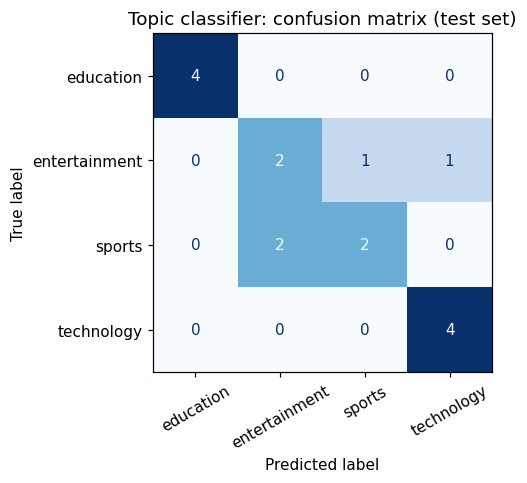

In [47]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    topic_df["text"], topic_df["label"], test_size=0.25, random_state=SEED, stratify=topic_df["label"])

topic_model = Pipeline([
    ("tfidf", TfidfVectorizer(preprocessor=lambda t: preprocess_text(t), ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000, C=10, random_state=SEED)),
])
topic_model.fit(Xt_train, yt_train)
yt_pred = topic_model.predict(Xt_test)

categories = sorted(topic_df["label"].unique())
print(f"Train: {len(Xt_train)} | Test: {len(Xt_test)} | Accuracy: {accuracy_score(yt_test, yt_pred):.2f}")
print(classification_report(yt_test, yt_pred, labels=categories, zero_division=0))

cm_topic = confusion_matrix(yt_test, yt_pred, labels=categories)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_topic, display_labels=categories).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                  xticks_rotation=30)
ax.set_title("Topic classifier: confusion matrix (test set)")
plt.tight_layout()
plt.show()

**Interpretation.** For multiclass problems `classification_report` gives precision, recall and F1 **per class**. With only 16 test messages (4 per class) these numbers are extremely noisy; they demonstrate the workflow, not real reliability.

**Note on the preprocessor.** We plugged our own `preprocess_text` into the vectorizer through `preprocessor=...`, so cleaning is part of the pipeline and applied identically at training and prediction time.

## 5.4 Prediction

In [48]:
def predict_topic(message, model=topic_model, top_k: int = 2) -> list:
    """Return the top_k most likely categories with probabilities."""
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please provide a non-empty message.")
    probs = model.predict_proba([message])[0]
    ranked = np.argsort(probs)[::-1][:top_k]
    return [(model.classes_[i], round(float(probs[i]), 2)) for i in ranked]

new_messages = [
    "The striker was injured before the league final",
    "A new app lets developers train machine learning models",
    "Exam timetable released for all students",
    "The singer announced a new album and a world tour",
    "The weather is lovely today",          # out-of-scope text: the model must still choose something
]
for message in new_messages:
    print(predict_topic(message), "<-", message)

[('sports', 0.56), ('entertainment', 0.15)] <- The striker was injured before the league final
[('technology', 0.7), ('education', 0.11)] <- A new app lets developers train machine learning models
[('education', 0.56), ('entertainment', 0.17)] <- Exam timetable released for all students
[('education', 0.34), ('entertainment', 0.29)] <- The singer announced a new album and a world tour
[('entertainment', 0.25), ('sports', 0.25)] <- The weather is lovely today


**Interpretation.** The last message belongs to **none** of our categories, yet the model still has to choose; its probabilities will be low and spread out. A real application needs an "unknown/other" category or a confidence threshold.

### Optional interactive prediction
Colab can ask you to type text with `input()`. We guard it with a flag so *Run all* never gets stuck waiting for you.

In [49]:
RUN_INTERACTIVE_TOPIC = False   # change to True and run the cell to type your own message

if RUN_INTERACTIVE_TOPIC:
    user_message = input("Type a short message: ")
    try:
        print(predict_topic(user_message))
    except ValueError as error:
        print("Oops:", error)
else:
    print("Interactive input is switched off. Set RUN_INTERACTIVE_TOPIC = True to try it.")

Interactive input is switched off. Set RUN_INTERACTIVE_TOPIC = True to try it.


## 5.5 Error analysis

Error analysis means studying the mistakes. It often tells you more than the accuracy number.

In [50]:
results = pd.DataFrame({"text": Xt_test.values, "true": yt_test.values, "predicted": yt_pred})
results["confidence"] = topic_model.predict_proba(Xt_test).max(axis=1).round(2)
wrong_topics = results[results["true"] != results["predicted"]]
if len(wrong_topics):
    print(wrong_topics.to_string(index=False))
else:
    print("No test errors on this split. Check low-confidence correct answers instead:")
    print(results.sort_values("confidence").head(3).to_string(index=False))

                                                       text          true     predicted  confidence
Fans loved the final episode of the popular television show entertainment        sports        0.40
          The marathon runners started early in the morning        sports entertainment        0.25
         The singer released an album with twelve new songs entertainment    technology        0.45
          The goalkeeper saved a penalty in the last minute        sports entertainment        0.25


**What to look for:** overlapping topics (a *technology* story about a *sports* app), too little data for a category, or ambiguous wording. The fixes are usually more and better data, not a fancier model.

## 5.6 Discussion: from workflow demo to deployment

With only a few dozen training sentences this model cannot generalize reliably; it demonstrates the **workflow** only. A real deployment would need:

* Thousands of labelled, representative examples, cleaned and checked for label errors.
* A proper evaluation protocol (cross-validation, a larger held-out set).
* An "other/unknown" class and confidence thresholds.
* Monitoring for **data drift** (language changes over time) and periodic retraining.
* Privacy rules for user text, and a human review path for important decisions.

**Practice task.** Add a fifth category, `health`, with at least eight sentences, retrain, and examine the new confusion matrix.

# MODULE 6 — Understanding Chatbots

**Concept.** A chatbot is a program that holds a conversation with a user.

**Why it matters.** Chatbots answer repetitive questions 24/7 in banking, education, shopping and government services.

**Analogy.** A receptionist: some follow a script exactly, some understand what you want, some look answers up, some improvise.

| Type | How it works | Strength | Weakness |
|---|---|---|---|
| **Rule-based** | `if` the message contains X, reply Y | Predictable, easy to build and audit | Breaks on anything unexpected |
| **Intent-based** | A classifier maps a message to an *intent* (greeting, refund, ...), each with a reply | Handles many phrasings | Needs training examples per intent |
| **Retrieval-based** | Finds the most similar stored answer (e.g. TF-IDF similarity, as in Module 8) | Answers come from approved text | Can only say what is stored |
| **Generative AI** | A neural model writes new text word by word | Flexible, fluent | May produce false statements |
| **LLM-based assistant** | A large generative model plus instructions, tools and documents | Very capable | Cost, hallucination, privacy, safety needs |

## 6.1 Build a rule-based chatbot

Design: small functions with one job each — normalize, detect intent by keywords, choose a reply, run the loop. No external service needed.

In [51]:
from typing import Optional

BOT_NAME = "NLPBuddy"

# Each rule: (intent name, keywords that trigger it, reply)
RULES = [
    ("greeting", {"hello", "hi", "hey", "namaste"}, f"Hello! I am {BOT_NAME}. Ask me about NLP."),
    ("how_are_you", {"how are you", "how do you do"}, "I'm a program, but I'm running fine. Thanks for asking!"),
    ("what_is_nlp", {"what is nlp", "define nlp", "meaning of nlp"},
     "NLP (Natural Language Processing) helps computers work with human language."),
    ("tokenization", {"token", "tokenization", "tokenize"},
     "Tokenization splits text into smaller units called tokens, such as words."),
    ("tfidf", {"tf-idf", "tfidf"},
     "TF-IDF gives high weight to words that are frequent in a document but rare in the corpus."),
    ("help", {"help", "what can you do"},
     "Try: 'what is nlp', 'tokenization', 'tf-idf', or say 'bye' to exit."),
    ("thanks", {"thanks", "thank you"}, "You're welcome!"),
]
EXIT_WORDS = {"bye", "exit", "quit"}


def normalize_message(message) -> str:
    """Lowercase, trim and collapse spaces; return '' for invalid input."""
    if not isinstance(message, str):
        return ""
    return " ".join(message.lower().strip().split())


def find_intent(message: str) -> Optional[str]:
    """Return the first matching intent name, or None.

    Single-word keywords must match whole words ('hi' must not match 'this');
    multi-word keywords are matched as phrases.
    """
    words = set(re.findall(r"[a-z\-']+", message))
    for intent, keywords, _ in RULES:
        for keyword in keywords:
            if " " in keyword:
                if keyword in message:
                    return intent
            elif keyword in words:
                return intent
    return None


def get_reply(message: str) -> str:
    """Choose a reply for one user message."""
    message = normalize_message(message)
    if not message:
        return "Please type something and I will try to help."
    intent = find_intent(message)
    for name, _, reply in RULES:
        if name == intent:
            return reply
    return "Sorry, I don't understand that yet. Type 'help' to see what I can do."


def chat(max_turns: int = 20) -> None:
    """Interactive loop. Type 'bye' to exit."""
    print(f"{BOT_NAME}: Hello! (type 'bye' to exit)")
    for _ in range(max_turns):
        message = input("You: ")
        if normalize_message(message) in EXIT_WORDS:
            print(f"{BOT_NAME}: Goodbye!")
            break
        print(f"{BOT_NAME}: {get_reply(message)}")

# Non-interactive demonstration (works in Run all): a scripted conversation
script = ["Hi", "What is NLP?", "tell me about tokenization", "this is a test", "", "tf-idf", "thanks", "bye"]
for user_message in script:
    if normalize_message(user_message) in EXIT_WORDS:
        print(f"You: {user_message}\n{BOT_NAME}: Goodbye!")
        break
    print(f"You: {user_message}\n{BOT_NAME}: {get_reply(user_message)}")

You: Hi
NLPBuddy: Hello! I am NLPBuddy. Ask me about NLP.
You: What is NLP?
NLPBuddy: NLP (Natural Language Processing) helps computers work with human language.
You: tell me about tokenization
NLPBuddy: Tokenization splits text into smaller units called tokens, such as words.
You: this is a test
NLPBuddy: Sorry, I don't understand that yet. Type 'help' to see what I can do.
You: 
NLPBuddy: Please type something and I will try to help.
You: tf-idf
NLPBuddy: TF-IDF gives high weight to words that are frequent in a document but rare in the corpus.
You: thanks
NLPBuddy: You're welcome!
You: bye
NLPBuddy: Goodbye!


**Interpretation.** Greetings and known questions get replies; the unknown message `this is a test` gets a graceful fallback (and does **not** trigger the greeting rule even though it contains the letters "hi" — the *common mistake* of substring matching, which our whole-word check avoids); the empty message gets a polite prompt; `bye` exits.

To chat for real, run `chat()` in a new cell and type messages in the box that appears.

In [52]:
RUN_INTERACTIVE_CHAT = False   # set True, then run this cell
if RUN_INTERACTIVE_CHAT:
    chat()
else:
    print("Chat loop is switched off so 'Run all' does not wait for input.")

Chat loop is switched off so 'Run all' does not wait for input.


**Practice task.** Add a rule for the question "who created you" and one for "what is stemming". Why is rule order important when two rules could both match?

## 6.2 How to extend it

| Step up | Idea |
|---|---|
| Intents | Replace keyword lists with a classifier trained on example sentences per intent (Module 5 workflow) |
| Retrieval | Store question–answer pairs; reply with the answer whose question is most similar (TF-IDF + cosine similarity, Module 8) |
| APIs | Call a weather, timetable or database service to produce live answers |
| Language models | Let an LLM write replies, ideally grounded in approved documents |

## 6.3 Limitations, privacy, hallucination and safety

* **Limits of rules:** every new phrasing needs a new rule; "Could you explain NLP?" would currently fail.
* **Privacy:** user messages may contain personal data. Collect the minimum, say what you store, protect it, and do not log secrets.
* **Hallucination:** generative models can produce confident but false statements. Ground answers in trusted sources and allow "I don't know".
* **Safety:** filter harmful requests, avoid medical/legal/financial advice without human oversight, and offer a path to a human.
* **Demo vs production:** a production system adds authentication, logging, testing with real users, accessibility, fallback to human agents, monitoring and clear disclosure that users are talking to a bot.

# MODULE 7 — Image Recognition: How It Relates to AI and NLP

> **Important distinction.** Image recognition is mainly a **computer vision** task, not a traditional NLP task. It is included in a broader AI-applications curriculum because modern AI increasingly combines images and language (**multimodal AI**).

| Concept | Meaning | Example |
|---|---|---|
| Image classification | One label for the whole image | "cat" |
| Object detection | Labels *and locations* (boxes) of objects | "cat at (x, y, w, h), ball at ..." |
| Image captioning | A generated sentence describing the image | "A cat sitting on a sofa." |
| Vision-language model | A model trained on images paired with text | Answers "What colour is the sofa?" |
| Text prompt + image | The user sends a picture and a question | "Is this plant healthy?" |

**Predicted label vs generated caption.** A *label* comes from a fixed list of classes ("cat"). A *caption* is free-form text composed by a language-generating component, and can describe relationships and details not in any label list.

## 7.1 Conceptual workflow

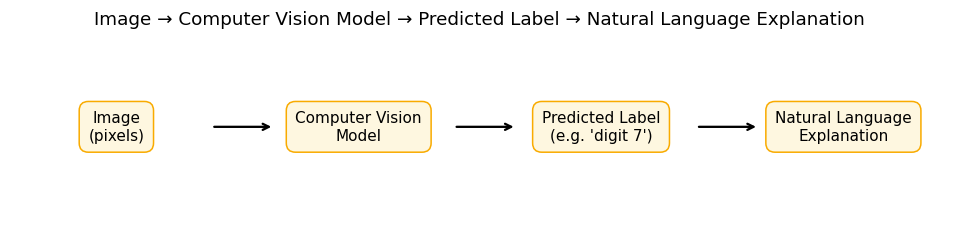

In [53]:
fig, ax = plt.subplots(figsize=(11, 2.2))
boxes = ["Image\n(pixels)", "Computer Vision\nModel", "Predicted Label\n(e.g. 'digit 7')", "Natural Language\nExplanation"]
for i, label in enumerate(boxes):
    ax.text(i * 2.3, 0, label, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.6", fc="#fef7e0", ec="#f9ab00"))
    if i < len(boxes) - 1:
        ax.annotate("", xy=(i * 2.3 + 1.5, 0), xytext=(i * 2.3 + 0.9, 0),
                    arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-1, 7.9)
ax.set_ylim(-1, 1)
ax.axis("off")
ax.set_title("Image → Computer Vision Model → Predicted Label → Natural Language Explanation")
plt.show()

## 7.2 A real (tiny) image-recognition demo that runs offline

Instead of a fake hard-coded prediction, we use a small **real** model on a **real** (but very small) image dataset that ships with scikit-learn: 8×8-pixel images of handwritten digits. No download is needed. This is *genuine* image classification (pixels in, label out); the "natural language explanation" step is a simple template we write, not a vision-language model.

Image array shape: (1797, 8, 8) (images, height, width)
Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Held-out accuracy on digits: 0.962


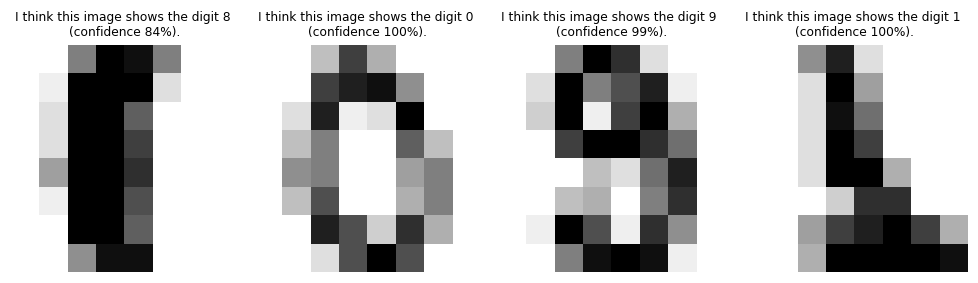

In [54]:
from sklearn.datasets import load_digits

digits = load_digits()
print("Image array shape:", digits.images.shape, "(images, height, width)")
print("Classes:", [int(c) for c in digits.target_names])

Xd_train, Xd_test, yd_train, yd_test, img_train, img_test = train_test_split(
    digits.data, digits.target, digits.images, test_size=0.25, random_state=SEED, stratify=digits.target)

digit_model = LogisticRegression(max_iter=2000, random_state=SEED)
digit_model.fit(Xd_train, yd_train)
print("Held-out accuracy on digits:", round(digit_model.score(Xd_test, yd_test), 3))

def explain_digit_prediction(image_8x8: np.ndarray) -> str:
    """Turn the model's predicted label into a short natural-language sentence."""
    flat = image_8x8.reshape(1, -1)
    probs = digit_model.predict_proba(flat)[0]
    label = int(np.argmax(probs))
    return f"I think this image shows the digit {label} (confidence {probs[label]:.0%})."

fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, img in zip(axes, img_test[:4]):
    ax.imshow(img, cmap="gray_r")
    ax.axis("off")
    ax.set_title(explain_digit_prediction(img).replace("(", "\n("), fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation.** The model produced a **label** (a digit). The sentence beneath each image is a **template-based explanation**, not a generated caption: the system does not "see" in a human way and cannot describe anything outside its ten classes.

**Common mistake:** presenting a hard-coded answer as recognition. Here the prediction really comes from a trained model — but one trained on tiny, clean digits, so it would fail on, say, a photo of a street.

**Practice task.** Show the first misclassified test image and its (wrong) explanation.

## 7.3 How NLP connects

* **Captioning:** an image encoder produces features; a language decoder writes a sentence.
* **Visual question answering:** the question text and the image are both inputs.
* **Search by text:** models trained on image–text pairs let you search photos with words.

## 7.4 OPTIONAL extension: a pretrained image classifier

> **This section is optional and not needed for anything else in the notebook.** It is switched **off** by default.

| Item | Details |
|---|---|
| Dependencies | `transformers`, `torch`, `pillow` (preinstalled on Colab; otherwise `pip install transformers torch pillow`) |
| Model | `microsoft/resnet-50` from the Hugging Face Hub (about 100 MB download; needs internet) |
| Resources | CPU is fine for one image (a few seconds); first run downloads the model |
| Image | Upload your own file in Colab (folder icon), then set `IMAGE_PATH` |
| Fallback | If anything fails, the cell prints a message and the notebook continues with the offline demo above |

In [55]:
RUN_OPTIONAL_PRETRAINED_MODEL = False    # set True to try it
IMAGE_PATH = "my_image.jpg"              # upload a file with this name first

if RUN_OPTIONAL_PRETRAINED_MODEL:
    try:
        from transformers import pipeline
        classifier_pipe = pipeline("image-classification", model="microsoft/resnet-50")
        for pred in classifier_pipe(IMAGE_PATH)[:3]:
            print(f"{pred['label']}: {pred['score']:.1%}")
    except Exception as error:   # broad on purpose: this is an optional extra
        print("Optional model could not run (", type(error).__name__, ").",
              "Continue with the offline demo; nothing else depends on this cell.")
else:
    print("Optional pretrained-model demo is switched off (this is the default).")

Optional pretrained-model demo is switched off (this is the default).


# MODULE 8 — Recommendation Systems and NLP

**Concept.** A *recommendation system* suggests items (books, courses, videos, products) a person is likely to find useful.

**Why it matters.** Platforms use recommendations to help people find items among thousands of choices.

**Analogy.** A librarian who says: "You liked this book about robots; here are two similar ones."

| Approach | Idea | Needs |
|---|---|---|
| **Content-based** | Recommend items whose *content* (descriptions, tags, reviews) is similar to items you liked | Item text/metadata |
| **Collaborative filtering** | Recommend what *similar users* liked | A history of many users' ratings |

**How text helps.** Descriptions, titles, tags and reviews can be turned into TF-IDF vectors (Module 3). Items with similar vectors are similar in content.

**Similarity and ranking.** *Cosine similarity* measures the angle between two vectors: 1 means the same direction (same word-weight pattern), 0 means no shared words (for non-negative TF-IDF). Ranking sorts items by similarity, highest first.

**Cold-start problem.** A brand-new user (no history) or new item (no ratings) cannot be handled by collaborative filtering. Content-based methods can still describe a new *item* from its text, but still know nothing about a new *user's* taste.

**Recommendation vs classification.** Classification assigns one label from a fixed set ("sports"). Recommendation produces a *ranked list* of items, personalised or related to a chosen item.

## 8.1 A small self-contained dataset

In [56]:
from sklearn.metrics.pairwise import cosine_similarity

catalog = pd.DataFrame([
    ("Intro to Python Programming", "Learn python programming basics: variables, loops, functions and data structures for beginners"),
    ("Data Analysis with Pandas", "Analyse data tables with python and pandas: cleaning, grouping, statistics and data visualisation"),
    ("Machine Learning Foundations", "Machine learning with python and scikit-learn: classification, regression, model evaluation and data preparation"),
    ("Deep Learning with Neural Networks", "Deep learning: train neural networks for images and text, extending machine learning classification"),
    ("Natural Language Processing Basics", "Text classification and sentiment analysis in python: tokenization, tfidf features, machine learning models and chatbots"),
    ("Computer Vision Essentials", "Computer vision: image classification and object detection using neural networks and deep learning"),
    ("Web Development with Flask", "Build web applications and apis with python flask: routes, templates, forms and databases"),
    ("Cybersecurity Fundamentals", "Network and system security: encryption, passwords, threats and secure software practices"),
    ("Embedded Systems and IoT", "Program microcontrollers, sensors and wireless devices to build internet of things embedded projects"),
    ("Statistics for Data Science", "Probability, distributions and hypothesis testing for data analysis and machine learning"),
], columns=["title", "description"])
print(catalog.shape, "| duplicate titles:", catalog["title"].duplicated().sum())
catalog[["title"]]

(10, 2) | duplicate titles: 0


,title
0,Intro to Python Programming
1,Data Analysis with Pandas
2,Machine Learning Foundations
3,Deep Learning with Neural Networks
4,Natural Language Processing Basics
5,Computer Vision Essentials
6,Web Development with Flask
7,Cybersecurity Fundamentals
8,Embedded Systems and IoT
9,Statistics for Data Science


## 8.2 Feature extraction and similarity matrix

We fit the vectorizer on each item's *title plus description*, the full set of items we recommend from. (In a supervised project this would be leakage if we then evaluated on the same items; here there is no train/test split because we are not predicting labels.)

TF-IDF matrix shape: (10, 87) | similarity matrix shape: (10, 10)


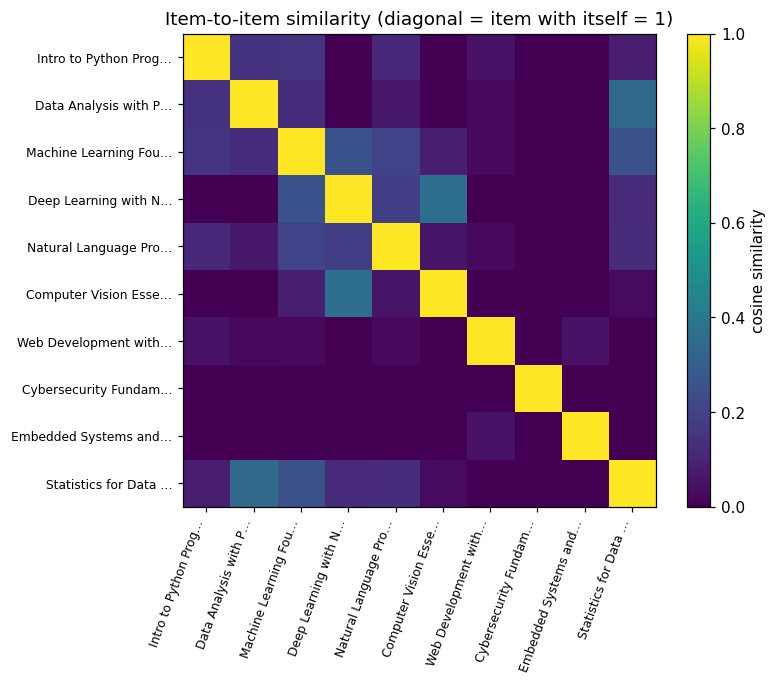

In [57]:
rec_vectorizer = TfidfVectorizer(stop_words="english")
catalog["text"] = catalog["title"] + ". " + catalog["description"]      # use title AND description
item_vectors = rec_vectorizer.fit_transform(catalog["text"])
similarity = cosine_similarity(item_vectors)          # shape: (n_items, n_items)
print("TF-IDF matrix shape:", item_vectors.shape, "| similarity matrix shape:", similarity.shape)

short_names = [t if len(t) < 22 else t[:20] + "…" for t in catalog["title"]]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
image = ax.imshow(similarity, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(short_names)))
ax.set_xticklabels(short_names, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(short_names)))
ax.set_yticklabels(short_names, fontsize=8)
fig.colorbar(image, label="cosine similarity")
ax.set_title("Item-to-item similarity (diagonal = item with itself = 1)")
plt.tight_layout()
plt.show()

**Interpretation.** The bright diagonal is every item compared with itself (similarity exactly 1). Off the diagonal, brighter cells mark related courses. This is why we must **exclude the selected item itself** from recommendations: it will always rank first.

## 8.3 Ranking function with explanations

In [58]:
def explain_match(idx_a: int, idx_b: int, top_n: int = 3) -> list:
    """Return the shared words that contribute most to the similarity of two items."""
    shared_weight = item_vectors[idx_a].multiply(item_vectors[idx_b]).toarray().ravel()
    words = rec_vectorizer.get_feature_names_out()
    top = np.argsort(shared_weight)[::-1][:top_n]
    return [words[i] for i in top if shared_weight[i] > 0]


def recommend(title: str, top_n: int = 3) -> pd.DataFrame:
    """Recommend items similar to `title` (never the item itself)."""
    matches = catalog.index[catalog["title"] == title]
    if len(matches) == 0:
        raise ValueError(f"Unknown title: {title!r}. Choose one of: {list(catalog['title'])}")
    idx = int(matches[0])
    scores = similarity[idx].copy()
    scores[idx] = -1.0                       # exclude the selected item itself
    ranked = np.argsort(scores)[::-1][:top_n]
    return pd.DataFrame({
        "recommended": catalog.loc[ranked, "title"].values,
        "similarity": scores[ranked].round(3),
        "because_of_words": [", ".join(explain_match(idx, j)) or "(no shared words)" for j in ranked],
    })

selected = "Natural Language Processing Basics"
print("Because you selected:", selected)
rec_table = recommend(selected, top_n=3)
assert selected not in rec_table["recommended"].values       # the item must never recommend itself
rec_table

Because you selected: Natural Language Processing Basics


,recommended,similarity,because_of_words
0,Machine Learning Foundations,0.200,"machine, learning, classification"
1,Deep Learning with Neural Networks,0.185,"learning, text, machine"
2,Statistics for Data Science,0.128,"analysis, machine, learning"


**Interpretation.** The table lists the closest items and the words that explain each match. Similarity values are modest because every description is only one short sentence; with real, longer descriptions the scores are more informative. Showing *why* an item was recommended builds trust and helps debug strange results.

In [59]:
print(recommend("Embedded Systems and IoT", top_n=3).to_string(index=False))
try:
    recommend("Nonexistent Course")
except ValueError as error:
    print("\nInput check works:", str(error)[:60], "...")

                       recommended  similarity  because_of_words
        Web Development with Flask       0.047             build
       Statistics for Data Science       0.000 (no shared words)
Deep Learning with Neural Networks       0.000 (no shared words)

Input check works: Unknown title: 'Nonexistent Course'. Choose one of: ['Intro  ...


**Notice** that *Embedded Systems and IoT* has almost no related items: no other course shares its vocabulary, so the scores fall to zero. A real recommender should be able to say "no good match" instead of forcing a list.

### Handling a brand-new item (cold start for items)

A new course arrives with no ratings. Because we use *content*, we can still place it: transform its description with the **already fitted** vectorizer and compare.

In [60]:
def recommend_for_new_text(description: str, top_n: int = 3) -> pd.DataFrame:
    """Find catalog items most similar to a new description (uses the fitted vectorizer)."""
    if not isinstance(description, str) or not description.strip():
        raise ValueError("Provide a non-empty description.")
    new_vec = rec_vectorizer.transform([description])
    scores = cosine_similarity(new_vec, item_vectors).ravel()
    ranked = np.argsort(scores)[::-1][:top_n]
    return pd.DataFrame({"recommended": catalog.loc[ranked, "title"].values, "similarity": scores[ranked].round(3)})

recommend_for_new_text("A course on building sentiment analysis tools for customer reviews using text classification")

,recommended,similarity
0,Natural Language Processing Basics,0.397
1,Computer Vision Essentials,0.187
2,Deep Learning with Neural Networks,0.148


**Common mistake:** re-fitting the vectorizer for each new item. That changes the vocabulary and IDF values and makes old and new vectors incomparable.

### Limitations to remember

* **Data leakage:** if you evaluate a recommender by hiding a user's item, make sure the item's text did not influence the vocabulary or similarity used for the test, and never "recommend" something the user already knows from the test fold.
* **Popularity bias:** collaborative systems tend to push already-popular items; content-based systems can instead over-recommend near-duplicates (a *filter bubble*).
* **Cold start:** new *users* still have no taste profile; content features help only with new *items*.
* **Text quality:** two items described with different words but the same meaning look dissimilar to TF-IDF (embeddings help, Module 11).
* **Evaluation:** with 10 items this is a demonstration of the mechanism, not a measurable product.

**Practice task.** Add three items to `catalog` (re-run the cells above) and check that a related existing course ranks them highly.

# MODULE 9 — Mini Project: Smart Customer Feedback Analyzer

**Goal.** Take a batch of customer comments, classify each as positive or negative, explain the decision in plain words, summarize the batch and draw a chart.

This project reuses ideas from every earlier module:

| Step | Module |
|---|---|
| 1. Text input and validation | 2 |
| 2. Basic text inspection | 1–2 |
| 3. Optional preprocessing | 2 |
| 4. TF-IDF features | 3 |
| 5. Sentiment classifier | 4 |
| 6. Beginner-friendly explanations | 4 |
| 7. Summary + 8. visualization | 4 |
| 9. Error handling | all |
| 10. Responsible use | 9.6 below |

We keep it simple: plain functions with meaningful names, no classes, no frameworks.

## 9.1 Text input and basic inspection

In [61]:
def inspect_feedback(text: str) -> dict:
    """Basic facts about one comment: size, shouting, digits, question marks."""
    return {
        "characters": len(text),
        "words": len(text.split()),
        "has_digits": any(ch.isdigit() for ch in text),
        "mostly_uppercase": sum(c.isupper() for c in text) > 0.6 * max(1, sum(c.isalpha() for c in text)),
        "is_question": "?" in text,
    }

def clean_feedback_list(raw_items) -> tuple:
    """Keep usable comments; report how many were skipped (None, numbers, empty strings)."""
    if raw_items is None:
        raise ValueError("No feedback supplied.")
    valid = [item.strip() for item in raw_items if isinstance(item, str) and item.strip()]
    return valid, len(list(raw_items)) - len(valid)

sample_feedback = [
    "The delivery was quick and the packaging was perfect",
    "Support ignored my emails and the problem is still not solved",
    "Great course, the teacher explains very clearly",
    "The app keeps crashing and it is really frustrating",
    "Not bad at all, I am happy with the quality",
    "   ",
    None,
    "The staff were rude and the room was dirty",
    "WORST EXPERIENCE EVER!!!",
    "Helpful team and a smooth refund process",
]
valid_feedback, skipped = clean_feedback_list(sample_feedback)
print(f"{len(valid_feedback)} usable comments, {skipped} skipped (empty or not text)")
print(inspect_feedback(valid_feedback[-2]))

8 usable comments, 2 skipped (empty or not text)
{'characters': 24, 'words': 3, 'has_digits': False, 'mostly_uppercase': True, 'is_question': False}


**Interpretation.** Two invalid entries (blank text and `None`) are reported instead of crashing. Inspection flags that the all-capitals comment is "shouting", which can matter for sentiment: this is a reason **not** to lowercase blindly, as discussed in Module 2.

## 9.2 Optional preprocessing

We *can* apply `preprocess_text` from Module 2 before vectorizing. For a model trained on only about 100 sentences, heavy cleaning removes information, so we leave it **off by default** and use TF-IDF's own lowercasing. Compare:

In [62]:
example_comment = "The staff were NOT helpful, and I'm very disappointed!"
print("Original      :", example_comment)
print("Preprocessed  :", preprocess_text(example_comment))

Original      : The staff were NOT helpful, and I'm very disappointed!
Preprocessed  : staff not helpful very disappointed


## 9.3 Training the model (TF-IDF + Logistic Regression)

We first estimate performance with **cross-validation** (several different train/test splits), which is more informative than one tiny split. Then we train a final model on all labelled data for use in the app.

In [63]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def build_feedback_model(use_preprocessing: bool = False) -> Pipeline:
    """TF-IDF (unigrams+bigrams) followed by Logistic Regression."""
    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b", sublinear_tf=True,
        preprocessor=(lambda t: preprocess_text(t, remove_stopwords=False)) if use_preprocessing else None)
    return Pipeline([("tfidf", vectorizer), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(build_feedback_model(), sentiment_df["text"], sentiment_df["label"], cv=cv)
print("Cross-validated accuracy per fold:", cv_scores.round(2), "| mean:", cv_scores.mean().round(2))

feedback_model = build_feedback_model().fit(sentiment_df["text"], sentiment_df["label"])
print("Final model trained on", len(sentiment_df), "labelled comments.")

Cross-validated accuracy per fold: [0.62 0.96 0.83 0.58] | mean: 0.75
Final model trained on 96 labelled comments.


**Interpretation.** The fold scores vary, which signals how unstable estimates are with so little data (the fold scores range widely). We report them honestly rather than quoting only the best number. The final model uses all data because, once evaluated, more data is better; its own accuracy on that same data would be meaningless, so we do not report it.

## 9.4 Predictions, explanations, summary and chart

                                                      comment sentiment  confidence                       key_words  needs_review
         The delivery was quick and the packaging was perfect  positive        0.56     quick, perfect, was perfect          True
Support ignored my emails and the problem is still not solved  negative        0.54      not, my emails, ignored my          True
              Great course, the teacher explains very clearly  positive        0.64     great, teacher, the teacher         False
          The app keeps crashing and it is really frustrating  negative        0.53 keeps, keeps crashing, crashing          True
                  Not bad at all, I am happy with the quality  negative        0.54          not, happy, happy with          True
                   The staff were rude and the room was dirty  negative        0.61                 rude, was, were         False
                                     WORST EXPERIENCE EVER!!!  negative        0.51       

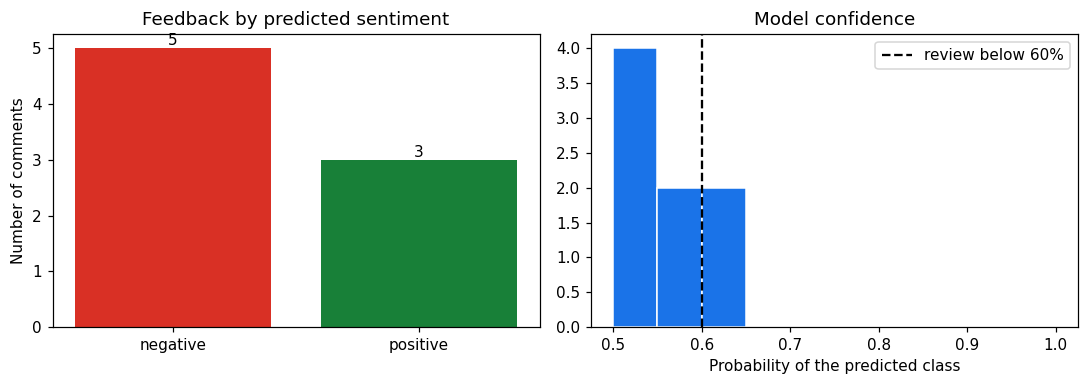

In [64]:
LOW_CONFIDENCE = 0.60

def explain_prediction(model: Pipeline, text: str, top_n: int = 3) -> list:
    """Words that pushed the model toward its decision (largest weight x TF-IDF value)."""
    vectorizer, classifier = model.named_steps["tfidf"], model.named_steps["clf"]
    vector = vectorizer.transform([text])
    contribution = vector.multiply(classifier.coef_[0]).toarray().ravel()   # + => positive, - => negative
    names = vectorizer.get_feature_names_out()
    predicted_positive = classifier.predict(vector)[0] == "positive"
    order = np.argsort(contribution)
    chosen = order[::-1][:top_n] if predicted_positive else order[:top_n]
    return [names[i] for i in chosen if contribution[i] != 0 and (contribution[i] > 0) == predicted_positive]


def analyze_feedback(model: Pipeline, raw_items) -> pd.DataFrame:
    """Return one row per usable comment: sentiment, confidence, key words, review flag."""
    comments, _ = clean_feedback_list(raw_items)
    if not comments:
        return pd.DataFrame(columns=["comment", "sentiment", "confidence", "key_words", "needs_review"])
    probs = model.predict_proba(comments)
    best = probs.argmax(axis=1)
    return pd.DataFrame({
        "comment": comments,
        "sentiment": model.classes_[best],
        "confidence": probs.max(axis=1).round(2),
        "key_words": [", ".join(explain_prediction(model, c)) for c in comments],
        "needs_review": probs.max(axis=1) < LOW_CONFIDENCE,
    })


def summarize_feedback(results: pd.DataFrame) -> dict:
    """Counts, percentages and the number of comments a human should double-check."""
    total = len(results)
    if total == 0:
        return {"total": 0}
    counts = results["sentiment"].value_counts()
    return {"total": total,
            "positive": int(counts.get("positive", 0)),
            "negative": int(counts.get("negative", 0)),
            "percent_positive": round(float(100 * counts.get("positive", 0) / total), 1),
            "needs_review": int(results["needs_review"].sum())}


def plot_feedback_summary(results: pd.DataFrame) -> None:
    """Bar chart of sentiment counts and a histogram of model confidence."""
    if results.empty:
        print("Nothing to plot.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    counts = results["sentiment"].value_counts().reindex(["negative", "positive"], fill_value=0)
    axes[0].bar(counts.index, counts.values, color=["#d93025", "#188038"])
    axes[0].set_title("Feedback by predicted sentiment")
    axes[0].set_ylabel("Number of comments")
    for i, v in enumerate(counts.values):
        axes[0].text(i, v + 0.05, str(v), ha="center")
    axes[1].hist(results["confidence"], bins=np.linspace(0.5, 1.0, 11), color="#1a73e8", edgecolor="white")
    axes[1].axvline(LOW_CONFIDENCE, color="black", linestyle="--", label=f"review below {LOW_CONFIDENCE:.0%}")
    axes[1].set_title("Model confidence")
    axes[1].set_xlabel("Probability of the predicted class")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


results = analyze_feedback(feedback_model, sample_feedback)
print(results.to_string(index=False))
print("\nSummary:", summarize_feedback(results))
plot_feedback_summary(results)

**Interpretation.** The table shows the decision, how sure the model is, and the words behind it. Comments with confidence below 60% are flagged for a human, which is a basic safeguard. Because the training set is tiny, most confidences are modest, so many rows are flagged: that is the model being honestly unsure, not a bug. Look closely at "Not bad at all, I am happy with the quality": a human reads it as positive, but the model may get it wrong. Negation is hard, and 96 training sentences are not enough to learn it reliably. The summary and charts turn many comments into a quick overview.

**Common mistake:** trusting a single predicted label without looking at the confidence or the reason. Check the flagged rows manually.

## 9.5 Interactive interface (with a non-interactive fallback)

The widget below works in Colab through `ipywidgets`. If widgets are unavailable the cell prints a message; the demonstration above (the *non-interactive fallback*) already shows the full workflow, and you can always call `analyze_feedback(feedback_model, ["your", "comments"])` directly.

In [65]:
USE_WIDGET = True

if USE_WIDGET:
    try:
        import ipywidgets as widgets
        from IPython.display import display

        box = widgets.Textarea(placeholder="One comment per line", layout=widgets.Layout(width="95%", height="110px"))
        button = widgets.Button(description="Analyze", button_style="primary")
        output = widgets.Output()

        def on_click(_):
            with output:
                output.clear_output()
                lines = [line for line in box.value.splitlines()]
                try:
                    res = analyze_feedback(feedback_model, lines)
                    if res.empty:
                        print("Please type at least one comment.")
                    else:
                        print(res.to_string(index=False))
                        print("Summary:", summarize_feedback(res))
                except Exception as error:          # keep the interface alive for beginners
                    print("Something went wrong:", error)

        button.on_click(on_click)
        display(box, button, output)
    except ImportError:
        print("ipywidgets is not available. Use analyze_feedback(feedback_model, [...]) instead.")
else:
    print("Widget switched off. Use analyze_feedback(feedback_model, [...]) instead.")

Textarea(value='', layout=Layout(height='110px', width='95%'), placeholder='One comment per line')

Button(button_style='primary', description='Analyze', style=ButtonStyle())

Output()

## 9.6 Limitations and responsible use

**Classroom prototype vs deployable product**

| This prototype | A deployable product would need |
|---|---|
| 96 hand-written training comments | Thousands of real, representative, carefully labelled comments |
| Binary labels only | Neutral/mixed sentiment, topics (delivery, price, support), languages used by your customers |
| Single author's writing style | Diverse authors, dialects, spelling variants, emojis |
| One quick cross-validation | Held-out test data, ongoing monitoring, error analysis by group |
| No privacy controls | Consent, anonymisation, retention limits, secure storage |

**Responsible use**

* Do not use automatic sentiment scores alone to judge or penalise a person (a student, an employee, a customer).
* Models inherit bias from training data. Test on text from different groups, and review disagreements.
* Sarcasm, mixed opinions and cultural expressions will be misread; keep a human in the loop, especially for low-confidence rows.
* Tell people when their text is being analysed and avoid collecting personal data you do not need.

# MODULE 10 — Exercises, Assignments, and Assessment

Questions progress from recall to application and simple analysis. Attempt them first; the answer key is in **Section 10.8**, separate from the questions.

## 10.1 Ten conceptual questions

1. In your own words, what is NLP, and how is it different from simply searching for a word in a file?
2. Why can a computer not "read" text the way a person does?
3. Give two examples of lexical ambiguity.
4. Distinguish AI, machine learning and deep learning.
5. Why is unstructured data harder to analyse than structured data?
6. What is the difference between a token, a word and a document?
7. Why can punctuation or capital letters carry useful information?
8. Why does a bag-of-words representation lose information?
9. What does the "inverse document frequency" part of TF-IDF try to capture?
10. Why must a test set stay unseen during training?

## 10.2 Ten short-answer questions

1. Name two differences between stemming and lemmatization.
2. Give an example in which removing stop words reverses meaning.
3. What does `ngram_range=(1, 2)` do?
4. What does `min_df=3` do?
5. Define precision in one sentence.
6. Define recall in one sentence.
7. Why is accuracy misleading when 95% of the examples belong to one class?
8. What is a confusion matrix?
9. What is the cold-start problem in recommendations?
10. What is a hallucination in a generative chatbot?

## 10.3 Ten code-completion exercises

Replace each `____` with the correct code. (Solutions run in Section 10.8.)

```python
# 1
vec = ____()                       # create a Bag-of-Words vectorizer
X = vec.fit_transform(docs)

# 2
print(X.____)                      # show (documents, features)

# 3
TfidfVectorizer(ngram_range=(____, ____))   # unigrams and bigrams

# 4
train_test_split(X, y, test_size=0.2, random_state=42, ____=y)   # keep class ratios

# 5
Pipeline([("tfidf", TfidfVectorizer()), ("clf", ____(max_iter=1000))])

# 6
model.____(["great product"])      # predict the label

# 7
scores = cosine_similarity(X[0], X).____()   # flatten the 1 x n result to a 1-D array

# 8
scores[____] = -1                  # stop the selected item (index idx) recommending itself

# 9
f1_score(y_true, y_pred, pos_label="positive", zero_division=____)

# 10
PorterStemmer().____("studies")    # reduce a word to its stem
```

## 10.4 Five debugging exercises

Find and fix the bug in each snippet.

**D1 — data leakage**
```python
vec = TfidfVectorizer()
X_train_vec = vec.fit_transform(X_train)
X_test_vec = vec.fit_transform(X_test)      # <- bug?
```

**D2 — missing resource**
```python
from nltk.tokenize import word_tokenize
print(word_tokenize("Hello world"))         # LookupError: Resource punkt not found
```

**D3 — counting words**
```python
from collections import Counter
print(Counter("to be or not to be").most_common(2))   # prints letters, not words
```

**D4 — meaning reversed**
```python
stops = set(stopwords.words("english"))
tokens = [w for w in "this is not good".split() if w not in stops]   # result: ['good']
```

**D5 — fake accuracy**
```python
model.fit(X_train, y_train)
print("Test accuracy:", model.score(X_train, y_train))   # <- bug?
```

## 10.5 Five practical mini-project ideas

1. **Fake review spotter:** classify short reviews as "genuine-looking" or "suspicious" using a dataset you build, and report what the model cannot know.
2. **Exam-question tagger:** label question-bank items by Bloom level or topic with TF-IDF + Logistic Regression.
3. **FAQ retrieval bot:** answer questions by finding the most similar stored question (TF-IDF + cosine similarity).
4. **Study-resource recommender:** recommend notes or videos from their descriptions for a topic you choose.
5. **Complaint router:** classify support messages into departments and flag low-confidence messages for a person.

## 10.6 Ten multiple-choice questions

Each has four options and exactly one correct answer. (The data is stored in code so the notebook can *verify* that every question has exactly four options and one valid answer index.)

In [66]:
# Each question: (question, [4 options], index_of_correct_option)
MCQS = [
    ("Which preprocessing step can silently reverse the sentiment of 'This is not good'?",
     ["Lowercasing the text", "Splitting the text into sentences", "Removing stop words including 'not'", "Tokenizing into words"], 2),
    ("In a document-term matrix, what does one row represent?",
     ["One vocabulary word", "One document", "One class label", "One character"], 1),
    ("Which term receives the HIGHEST TF-IDF weight in a document?",
     ["A term that appears in every document of the corpus", "A term that appears in no document", "A term frequent in this document but rare in the other documents", "A term that appears exactly once in every document"], 2),
    ("What is the correct way to avoid train/test leakage with a vectorizer?",
     ["Fit it on the full dataset before splitting", "Fit it on the training data only, then transform the test data", "Fit it separately on the test data", "Never use a vectorizer"], 1),
    ("Which metric answers: 'Of all truly positive items, how many did the model find?'",
     ["Recall", "Precision", "Accuracy", "Confusion matrix"], 0),
    ("Lemmatization differs from stemming because it:",
     ["Is always faster", "Uses a dictionary and part-of-speech information to return a valid base word", "Removes all stop words", "Converts words directly into numbers"], 1),
    ("A chatbot that replies with the stored answer whose question is most similar to the user's message is:",
     ["Rule-based using exact keywords only", "Retrieval-based", "A computer-vision system", "Purely generative"], 1),
    ("Image recognition is primarily:",
     ["A tokenization task", "A recommendation task", "A traditional NLP task", "A computer vision task"], 3),
    ("Two TF-IDF vectors have cosine similarity exactly 1.0. This means:",
     ["They share no words", "Their vectors point in the same direction", "The documents have opposite sentiment", "The documents are in different languages"], 1),
    ("The cold-start problem in recommendation means:",
     ["The system cannot start without a GPU", "A new user or item has too little history to base recommendations on", "The vocabulary is empty", "The stop-word list is too long"], 1),
]

# ---- automatic verification of the question bank ----
for number, (question, options, answer_index) in enumerate(MCQS, start=1):
    assert len(options) == 4, f"Q{number} must have 4 options"
    assert len(set(options)) == 4, f"Q{number} has duplicate options"
    assert isinstance(answer_index, int) and 0 <= answer_index < 4, f"Q{number} has an invalid answer index"
print("Verified:", len(MCQS), "questions, each with 4 distinct options and exactly one designated correct answer.\n")

# ---- display questions WITHOUT answers ----
for number, (question, options, _) in enumerate(MCQS, start=1):
    print(f"Q{number}. {question}")
    for letter, option in zip("ABCD", options):
        print(f"    {letter}) {option}")
    print()

Verified: 10 questions, each with 4 distinct options and exactly one designated correct answer.

Q1. Which preprocessing step can silently reverse the sentiment of 'This is not good'?
    A) Lowercasing the text
    B) Splitting the text into sentences
    C) Removing stop words including 'not'
    D) Tokenizing into words

Q2. In a document-term matrix, what does one row represent?
    A) One vocabulary word
    B) One document
    C) One class label
    D) One character

Q3. Which term receives the HIGHEST TF-IDF weight in a document?
    A) A term that appears in every document of the corpus
    B) A term that appears in no document
    C) A term frequent in this document but rare in the other documents
    D) A term that appears exactly once in every document

Q4. What is the correct way to avoid train/test leakage with a vectorizer?
    A) Fit it on the full dataset before splitting
    B) Fit it on the training data only, then transform the test data
    C) Fit it separately on t

## 10.7 Final practical challenge

**Create your own small text dataset and compare Bag of Words with TF-IDF for a text-classification task.**

Steps:
1. Choose two or three categories you care about (e.g. *study tips* vs *sports news*).
2. Write at least **10 sentences per category**, in your own words (no copying).
3. Run the template below (it already contains an example dataset, so it executes as is). Replace the example with your data.
4. Report cross-validated accuracy for BoW and TF-IDF, and **discuss honestly** whether the difference is meaningful given your dataset size.
5. Inspect at least three mistakes.

In [67]:
def compare_bow_vs_tfidf(frame: pd.DataFrame, n_splits: int = 3) -> pd.DataFrame:
    """Cross-validate BoW and TF-IDF with the same classifier; return mean/std accuracy."""
    if not {"text", "label"} <= set(frame.columns):
        raise ValueError("The DataFrame needs 'text' and 'label' columns.")
    smallest_class = frame["label"].value_counts().min()
    if smallest_class < n_splits:
        raise ValueError(f"Each class needs at least {n_splits} examples; the smallest has {smallest_class}.")
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    rows = []
    for name, vectorizer in [("Bag of Words", CountVectorizer()), ("TF-IDF", TfidfVectorizer())]:
        pipe = Pipeline([("vec", vectorizer), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])
        scores = cross_val_score(pipe, frame["text"], frame["label"], cv=folds)
        rows.append({"method": name, "mean_accuracy": round(scores.mean(), 3), "std": round(scores.std(), 3)})
    return pd.DataFrame(rows)

# Example dataset: REPLACE with your own (at least 10 sentences per class)
my_data = pd.DataFrame({
    "text": [
        "Make a timetable and revise every day", "Take short breaks while studying", "Practice past exam papers weekly",
        "Sleep well before the exam", "Summarise each chapter in your own words", "Study in a quiet room without phone",
        "Teach the topic to a friend to test yourself", "Start assignments early and avoid last minute stress",
        "Use flashcards to memorise key terms", "Ask the teacher when a concept is unclear",
        "The striker scored in the final minute", "Our team won the cricket series", "The runner broke the national record",
        "The coach announced the squad for the tournament", "A thrilling goal decided the football match",
        "The tennis star reached the final", "The captain hit a fast century", "The league match ended in a draw",
        "Fans cheered as the team lifted the trophy", "The goalkeeper saved two penalties",
    ],
    "label": ["study"] * 10 + ["sport"] * 10,
})
compare_bow_vs_tfidf(my_data)

,method,mean_accuracy,std
0,Bag of Words,0.905,0.067
1,TF-IDF,0.810,0.178


**Interpretation guide.** If both methods score about the same (very common on tiny datasets), say so; do not declare a winner from differences smaller than the standard deviation (`std`).

## 10.8 Answer key and solutions

### Conceptual questions: model answers

1. NLP builds methods that let computers work with *meaning and structure* of language (classify, translate, summarise, answer). Searching for a word only finds exact string matches.
2. Computers store text as character codes; meaning must be constructed through methods such as tokenization and learned features.
3. "bank" (river/money), "bat" (animal/cricket), "light" (weight/brightness).
4. AI: building systems that act intelligently; ML: AI that learns from data; DL: ML with many-layered neural networks.
5. It has no fixed fields; meaning is in the words and context, so it must be converted into numbers first.
6. A token is a unit produced by a tokenizer (may be punctuation or part of a word); a word is a linguistic unit; a document is a whole text unit being analysed.
7. "Great!!!" shows strong emotion; capitals can distinguish names ("Apple") or signal shouting.
8. It ignores word order and context ("dog bites man" = "man bites dog").
9. It lowers the weight of words that occur in many documents and raises the weight of rarer, more distinguishing words.
10. Otherwise the score measures memorization, not performance on new data.

### Short-answer questions: model answers

1. Stemming chops endings by rules and may give non-words; lemmatization uses a dictionary and part of speech to give real base words and is slower.
2. "not good" → "good" if "not" is removed.
3. It builds features from single words and two-word sequences.
4. It ignores words appearing in fewer than 3 documents.
5. Of the items predicted positive, the fraction that truly are positive.
6. Of the truly positive items, the fraction the model found.
7. A model that always predicts the majority class gets 95% accuracy while finding none of the minority class.
8. A table counting true vs predicted labels for every class.
9. A new user or item has no history, so history-based methods cannot recommend for it.
10. Fluent but false or invented content stated as if it were true.

In [68]:
# ---------- Answer key for the multiple-choice questions ----------
print("MCQ ANSWER KEY\n")
for number, (question, options, answer_index) in enumerate(MCQS, start=1):
    print(f"Q{number}: {'ABCD'[answer_index]}) {options[answer_index]}")

MCQ ANSWER KEY

Q1: C) Removing stop words including 'not'
Q2: B) One document
Q3: C) A term frequent in this document but rare in the other documents
Q4: B) Fit it on the training data only, then transform the test data
Q5: A) Recall
Q6: B) Uses a dictionary and part-of-speech information to return a valid base word
Q7: B) Retrieval-based
Q8: D) A computer vision task
Q9: B) Their vectors point in the same direction
Q10: B) A new user or item has too little history to base recommendations on


**MCQ explanations**

1. **C.** Removing "not" leaves "good", which looks positive. Lowercasing, sentence splitting and tokenizing do not delete negation.
2. **B.** Rows = documents, columns = vocabulary words.
3. **C.** TF-IDF rewards terms frequent in the document but rare elsewhere. A term in every document has the lowest IDF; a term in no document has no weight in any document.
4. **B.** Fit on training data only so no test information leaks.
5. **A.** Recall = found positives / all true positives. Precision concerns the items *predicted* positive.
6. **B.** Lemmatization looks words up in a dictionary with POS information; it is typically slower than stemming, and it does not remove stop words or by itself produce numbers.
7. **B.** Retrieval-based bots return an existing stored answer chosen by similarity. A purely generative bot writes new text.
8. **D.** Image recognition is computer vision (it links to NLP through multimodal systems).
9. **B.** Cosine similarity compares direction; 1.0 means the same direction (same relative word weights). Zero would mean no shared words (for TF-IDF).
10. **B.** Cold start is about missing history for new users or items.

In [69]:
# ---------- Solutions to the code-completion exercises (all executed) ----------
from nltk.stem import PorterStemmer as _PS

docs_cc = ["good movie", "bad movie", "good plot"]
y_cc = ["pos", "neg", "pos"]

# 1 and 2
vec = CountVectorizer()
X_cc = vec.fit_transform(docs_cc)
print("1-2:", X_cc.shape)
assert X_cc.shape == (3, 4)

# 3
assert TfidfVectorizer(ngram_range=(1, 2)).ngram_range == (1, 2)

# 4
parts = train_test_split(["a", "b", "c", "d", "e", "f", "g", "h"], ["x", "y"] * 4,
                         test_size=0.25, random_state=42, stratify=["x", "y"] * 4)
print("4:", len(parts[0]), "train /", len(parts[1]), "test, stratified")

# 5 and 6
model_cc = Pipeline([("tfidf", TfidfVectorizer()), ("clf", LogisticRegression(max_iter=1000))]).fit(docs_cc, y_cc)
print("5-6:", model_cc.predict(["good movie"]))

# 7 and 8
X_sim = TfidfVectorizer().fit_transform(["red apple", "red cherry", "blue sky"])
idx = 0
scores_cc = cosine_similarity(X_sim[idx], X_sim).ravel()
scores_cc[idx] = -1
print("7-8: best match for item 0 is item", int(scores_cc.argmax()))
assert int(scores_cc.argmax()) == 1

# 9
print("9:", f1_score(["positive", "negative"], ["negative", "negative"], pos_label="positive", zero_division=0))

# 10
print("10:", _PS().stem("studies"))

1-2: (3, 4)
4: 6 train / 2 test, stratified
5-6: ['pos']
7-8: best match for item 0 is item 1
9: 0.0
10: studi


**Code-completion answers:** 1 `CountVectorizer`; 2 `shape`; 3 `1, 2`; 4 `stratify`; 5 `LogisticRegression`; 6 `predict`; 7 `ravel` (or `flatten`); 8 `idx`; 9 `0`; 10 `stem`.

In [70]:
# ---------- Debugging solutions (fixed versions run here) ----------
train_docs = ["good phone", "bad phone", "good screen"]
test_docs = ["good battery"]

# D1: fit ONLY on training data; use transform (not fit_transform) on test data
vec_fixed = TfidfVectorizer()
X_train_vec = vec_fixed.fit_transform(train_docs)
X_test_vec = vec_fixed.transform(test_docs)
print("D1 fixed shapes:", X_train_vec.shape, X_test_vec.shape, "(same number of columns)")
assert X_train_vec.shape[1] == X_test_vec.shape[1]

# D2: download the tokenizer data first (the setup cell does this; shown again for clarity)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
print("D2 fixed:", word_tokenize("Hello world"))

# D3: Counter needs a list of words; Counter(string) counts characters
print("D3 fixed:", Counter("to be or not to be".split()).most_common(2))

# D4: keep negation words when removing stop words
stops_fixed = set(stopwords.words("english")) - {"not", "no", "nor"}
print("D4 fixed:", [w for w in "this is not good".split() if w not in stops_fixed])

# D5: evaluate on the TEST set; training accuracy is not test accuracy
fixed_model = Pipeline([("tfidf", TfidfVectorizer()), ("clf", LogisticRegression(max_iter=1000))]).fit(
    ["good phone", "bad phone", "good screen", "bad screen"], ["pos", "neg", "pos", "neg"])
print("D5 fixed (test score on unseen text):", fixed_model.score(["good camera", "bad camera"], ["pos", "neg"]))

D1 fixed shapes: (3, 4) (1, 4) (same number of columns)
D2 fixed: ['Hello', 'world']
D3 fixed: [('to', 2), ('be', 2)]
D4 fixed: ['not', 'good']
D5 fixed (test score on unseen text): 1.0


**Debugging explanations.** D1: `fit_transform` on test data re-learns the vocabulary from the test set (leakage, and different columns). D2: NLTK needs its data files downloaded. D3: `Counter("...")` iterates over characters. D4: "not" is in NLTK's default stop-word list. D5: scoring on the training set measures memorization.

**Mini-project ideas:** there is no single answer key; grade on (a) a clear, honest problem statement, (b) a sensible dataset with at least 10 examples per class, (c) train/test separation or cross-validation, (d) error analysis, and (e) an honest statement of limits.

# MODULE 11 — Revision and Further Learning

## 11.1 Concise revision sheet

| Topic | Remember |
|---|---|
| NLP | Methods that let computers work with human language |
| Preprocessing | Make text consistent; choices depend on the task; **never blindly remove negation** |
| Tokenization | Split text into characters, words or sentences |
| Stop words | Common words; remove for topic tasks, be careful for sentiment, do not remove for transformers |
| Stem vs lemma | Stem = rule-based chop (fast, crude); lemma = dictionary word (needs POS) |
| BoW | Word counts per document; ignores order |
| TF-IDF | Count × rarity across corpus, then normalized |
| n-grams | Word sequences (bigram "not good") |
| Leakage | Fit vectorizers on **training data only**; use a `Pipeline` |
| Metrics | Accuracy, precision, recall, F1, confusion matrix; small test sets are noisy |
| Chatbots | Rule → intent → retrieval → generative → LLM assistant |
| Recommenders | Content-based (text similarity) vs collaborative (user behaviour) |
| Responsible use | Representative data, human review, privacy, honest claims |

## 11.2 Glossary

In [71]:
glossary = {
    "Bag of Words": "Representation of a document by its word counts, ignoring order.",
    "Bigram": "A sequence of two consecutive words.",
    "Classification": "Assigning one label from a fixed set to an input.",
    "Corpus": "A collection of documents.",
    "Cosine similarity": "A measure of how similar the direction of two vectors is (1 = same direction).",
    "Data leakage": "Test-set information influencing training, which inflates scores.",
    "Document-term matrix": "Table with one row per document and one column per vocabulary word.",
    "Embedding": "A dense numeric vector that represents meaning of a word or text.",
    "F1-score": "Harmonic mean of precision and recall.",
    "Hallucination": "Fluent but false or invented output from a generative model.",
    "Lemmatization": "Reducing a word to its dictionary base form using vocabulary and part of speech.",
    "Large language model": "A very large neural network trained on lots of text to generate and understand language.",
    "Precision": "Fraction of predicted positives that are truly positive.",
    "Recall": "Fraction of true positives that were found.",
    "Sparse matrix": "A matrix that stores only its non-zero entries.",
    "Stemming": "Chopping word endings with rules to get a stem.",
    "Stop words": "Very common words such as 'the' and 'is'.",
    "Supervised learning": "Learning from examples that have correct labels.",
    "TF-IDF": "Term frequency weighted by inverse document frequency.",
    "Token": "A unit of text produced by tokenization.",
    "Tokenization": "Splitting text into tokens.",
    "Transformer": "A neural network architecture using attention; the basis of modern LLMs.",
    "Vocabulary": "The set of distinct tokens in a corpus.",
}
glossary_df = pd.DataFrame(sorted(glossary.items()), columns=["Term", "Meaning"])
print(len(glossary_df), "terms")
glossary_df

23 terms


,Term,Meaning
0,Bag of Words,Representation of a document by its word count...
1,Bigram,A sequence of two consecutive words.
2,Classification,Assigning one label from a fixed set to an input.
3,Corpus,A collection of documents.
4,Cosine similarity,A measure of how similar the direction of two ...
5,Data leakage,"Test-set information influencing training, whi..."
6,Document-term matrix,Table with one row per document and one column...
7,Embedding,A dense numeric vector that represents meaning...
8,F1-score,Harmonic mean of precision and recall.
9,Hallucination,Fluent but false or invented output from a gen...


## 11.3 Conceptual mind map and final end-to-end workflow

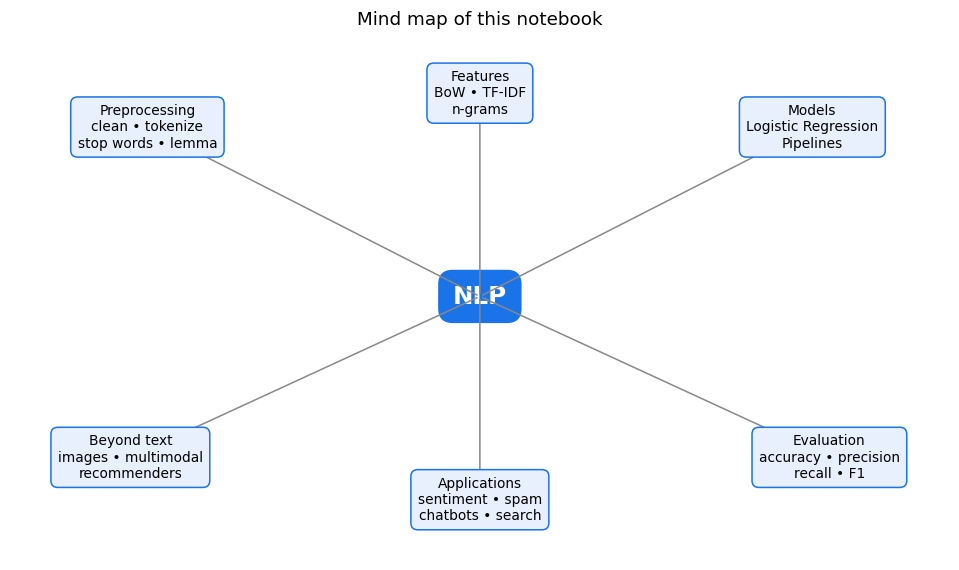

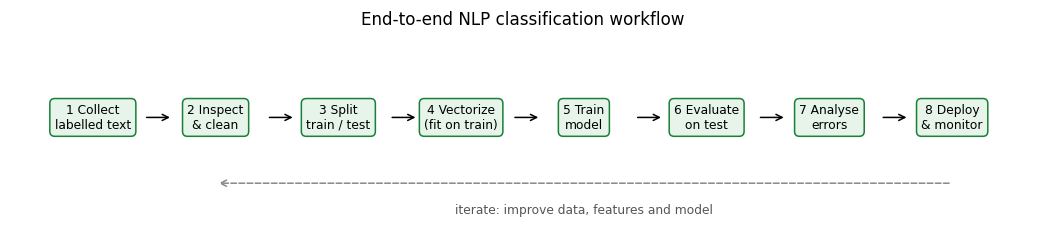

In [72]:
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.axis("off")
ax.set_xlim(0, 11)
ax.set_ylim(0, 6.2)

centre = (5.5, 3.1)
ax.text(*centre, "NLP", ha="center", va="center", fontsize=16, weight="bold",
        bbox=dict(boxstyle="round,pad=0.6", fc="#1a73e8", ec="none"), color="white")
branches = {
    "Preprocessing\nclean • tokenize\nstop words • lemma": (1.6, 5.1),
    "Features\nBoW • TF-IDF\nn-grams": (5.5, 5.5),
    "Models\nLogistic Regression\nPipelines": (9.4, 5.1),
    "Evaluation\naccuracy • precision\nrecall • F1": (9.6, 1.2),
    "Applications\nsentiment • spam\nchatbots • search": (5.5, 0.7),
    "Beyond text\nimages • multimodal\nrecommenders": (1.4, 1.2),
}
for label, (x, y) in branches.items():
    ax.annotate("", xy=(x, y), xytext=centre, arrowprops=dict(arrowstyle="-", color="#888"))
    ax.text(x, y, label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.5", fc="#e8f0fe", ec="#1a73e8"))
ax.set_title("Mind map of this notebook", fontsize=12)
plt.show()

# End-to-end workflow
fig, ax = plt.subplots(figsize=(12, 2.4))
stages = ["1 Collect\nlabelled text", "2 Inspect\n& clean", "3 Split\ntrain / test", "4 Vectorize\n(fit on train)",
          "5 Train\nmodel", "6 Evaluate\non test", "7 Analyse\nerrors", "8 Deploy\n& monitor"]
for i, label in enumerate(stages):
    ax.text(i * 1.5, 0, label, ha="center", va="center", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.4", fc="#e6f4ea", ec="#188038"))
    if i < len(stages) - 1:
        ax.annotate("", xy=(i * 1.5 + 0.98, 0), xytext=(i * 1.5 + 0.62, 0), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(1.5, -0.55), xytext=(10.5, -0.55),
            arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.0", ls="--", color="#888"))
ax.text(6.0, -0.8, "iterate: improve data, features and model", ha="center", fontsize=8, color="#555")
ax.set_xlim(-1, 11.5)
ax.set_ylim(-1, 0.7)
ax.axis("off")
ax.set_title("End-to-end NLP classification workflow", fontsize=11)
plt.show()

## 11.4 Workflow summary

1. **Define the task** (what exactly should the output be?).
2. **Collect and inspect data**; check labels, duplicates and missing values.
3. **Split** into train and test (stratified).
4. **Build a Pipeline**: vectorizer + classifier (+ any preprocessing).
5. **Train** on training data only.
6. **Evaluate** on the test data with metrics that suit the problem.
7. **Study errors**, improve data first, then features and model.
8. **Deploy cautiously**: monitor, collect feedback, keep humans in the loop.

## 11.5 Common beginner mistakes

| Mistake | Better practice |
|---|---|
| Running cells out of order | *Restart session and run all* |
| Removing "not" with stop words | Keep negations |
| Fitting the vectorizer on all data | Use a `Pipeline`; fit on training data only |
| Judging on training accuracy | Use unseen test data |
| Trusting tiny-dataset scores | Report uncertainty, use cross-validation, get more data |
| Using `.toarray()` on big matrices | Keep sparse matrices |
| Ignoring class imbalance | Check class counts, use precision/recall/F1 |
| Treating model confidence as truth | Review low-confidence cases |

## 11.6 Troubleshooting

| Symptom | Try this |
|---|---|
| `LookupError` for NLTK data | Re-run the setup cell; check internet connection |
| `ModuleNotFoundError` | `!pip install package-name`, then *Restart session* |
| Session crashed / out of memory | Use sparse matrices, smaller `max_features`, restart runtime |
| Different numbers than a classmate | Check library versions and that the random seed is unchanged |
| Widget does not appear | Use the non-interactive fallback functions |
| Plot does not appear | Make sure the cell ends with `plt.show()` |

## 11.7 Next steps

| Direction | What it adds | Level |
|---|---|---|
| **spaCy** | Fast production-grade tokenization, POS tagging, named entities | Next step |
| **Word embeddings** | Dense vectors where similar meanings are close | Intermediate |
| **Transformers (Hugging Face)** | Pretrained models for classification, QA, summarization | Advanced extension |
| **Large language models** | Generation, prompting, retrieval-augmented generation | Advanced extension |
| **Evaluation & ethics** | Bias testing, error analysis, privacy | Always relevant |

### Documentation and learning links

* Python: https://docs.python.org/3/tutorial/
* NLTK: https://www.nltk.org/
* scikit-learn text features: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
* scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html
* pandas: https://pandas.pydata.org/docs/
* Matplotlib: https://matplotlib.org/stable/
* Google Colab overview: https://colab.research.google.com/notebooks/basic_features_overview.ipynb
* spaCy 101 (*next step*): https://spacy.io/usage/spacy-101
* Hugging Face LLM/NLP course (*advanced extension*): https://huggingface.co/learn

## 11.8 Final verification: how to run this notebook top to bottom

1. Open the notebook in Google Colab (**File → Upload notebook**, or open from Google Drive).
2. Choose **Runtime → Restart session and run all** (a CPU runtime is fine; no GPU or API key is needed).
3. All core cells should complete without errors. The optional pretrained-image model (Section 7.4) and the interactive `input()` cells are switched **off** by default so *Run all* never waits or downloads large files.
4. The notebook needs internet only for the tiny NLTK downloads in the setup cell.
5. Exact numeric results can differ slightly across library versions; the random seed is fixed to 42 to keep runs consistent on the same versions.